# Etapa 11b · Os alunos do cenário B com o professor aberto maior

| | |
|---|---|
| **Pergunta** | Um professor aberto melhor faz alunos melhores? Quanto do ganho do professor chega ao aluno, e com ele os logits passam a valer mais que os rótulos? |
| **Entrada** | `entregas/01_dados/` (os pedidos); `entregas/11a_professor_aberto_maior/` (o professor novo: rótulos, logits e respostas do Qwen3-14B); `entregas/05b_professor_aberto/` e `entregas/05a_professor_fechado/` (o professor antigo e o fechado); `entregas/04b_intencao/`, `entregas/06_destilacao/` e `entregas/10a_encoder/` (as receitas e as respostas dos alunos antigos, do aluno A, do piso e do teto); e as 33 execuções desta etapa, gravadas por `especialista/experimentos/etapa11b.py` em `data/execucoes/11b_alunos_do_professor_maior/`. |
| **Entrega** | `entregas/11b_alunos_do_professor_maior/`: a temperatura de cada caminho (`decisao.json`), as comparações, o repasse, os modelos e as respostas dos alunos novos, e os sistemas declarados para o comparativo (`sistemas.json`). |
| **Pronto quando** | as regras estão gravadas antes do primeiro treino; as 33 execuções leram o professor novo com a receita dos alunos antigos; a temperatura saiu de `dev` pela regra da Etapa 6 e o teste só foi aberto para quem a regra previa; toda comparação da lista fechada está calculada em `dev` e no teste; as comparações dos alunos antigos, refeitas aqui, fecham com as entregues; nada das Etapas 6 e 10a mudou. |

Este notebook não treina nada. Os treinos rodaram numa cadeia só (`etapa11b rodada`), a temperatura e as contas foram gravadas por `etapa11b temperatura` e `etapa11b calcular`. Aqui só se lê o que ficou gravado.

**Artigos de apoio.** Cada referência foi conferida na API do arXiv (título, autores e data) e teve o **resumo** lido; o que cada resumo sustenta, e o que não sustenta, está na seção 10.

- Hinton, Vinyals & Dean, *Distilling the Knowledge in a Neural Network*, [arXiv 1503.02531](https://arxiv.org/abs/1503.02531): a perda do aluno B2, com temperatura.
- Cho & Hariharan, *On the Efficacy of Knowledge Distillation*, [arXiv 1910.01348](https://arxiv.org/abs/1910.01348): um professor mais exato não faz, por si só, um aluno melhor.
- Mirzadeh et al., *Improved Knowledge Distillation via Teacher Assistant*, [arXiv 1902.03393](https://arxiv.org/abs/1902.03393): a distância entre professor e aluno.
- Menon et al., *Why distillation helps: a statistical perspective*, [arXiv 2005.10419](https://arxiv.org/abs/2005.10419): o valor dos logits depende de quão bem aproximam as probabilidades de classe.
- Yuan et al., *Revisiting Knowledge Distillation via Label Smoothing Regularization*, [arXiv 1909.11723](https://arxiv.org/abs/1909.11723): parte do ganho dos alvos suaves é regularização (o controle do B2).
- Stanton et al., *Does Knowledge Distillation Really Work?*, [arXiv 2106.05945](https://arxiv.org/abs/2106.05945): imitar o professor e acertar a tarefa são medidas diferentes.
- Furlanello et al., *Born Again Neural Networks*, [arXiv 1805.04770](https://arxiv.org/abs/1805.04770): um aluno pode passar o seu professor.

**Seções**

1. O que muda e o que não muda
2. A temperatura do aluno B2, em `dev`
3. Os alunos novos e os antigos
4. O professor melhor faz alunos melhores?
5. Quanto do ganho do professor chega ao aluno
6. O que os logits valem com cada professor
7. O aluno ao lado do seu professor e do aluno A
8. Onde `dev` e teste discordam
9. Conferência com as etapas anteriores e custo
10. O que os artigos sustentam
11. Entrega
12. Resposta

In [1]:
import json
import re
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import qualidade
from especialista.avaliacao.previsao import carregar_previsoes, ouro
from especialista.caminhos import ENTREGAS, RAIZ
from especialista.dados import massive
from especialista.experimentos import etapa6, etapa11b

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PROFESSOR, ANTIGO = etapa11b.PROFESSOR_NOVO, etapa11b.PROFESSOR_ANTIGO
RODADA = etapa11b.pasta_da_rodada(PROFESSOR)          # regras, temperatura, contas e registros do professor
CALCULO = RODADA / "calculo"                          # gravado por `python -m especialista.experimentos.etapa11b calcular`
PASTA = ENTREGAS / etapa11b.ETAPA
CAMINHOS, TRES, SO_LOGITS = etapa11b.CAMINHOS, etapa11b.TRES, etapa11b.SO_LOGITS

ler = lambda nome: pd.read_csv(CALCULO / f"{nome}.csv")
qual, comp, difs, reps = ler("qualidade"), ler("comparacoes"), ler("diferencas_de_diferencas"), ler("repasses")
temps, fracoes, concorda, conf, treinos = ler("temperaturas"), ler("fracao_do_caminho"), ler("concordancia_com_o_professor"), ler("conferencia"), ler("treinos")
regras = etapa11b.exigir_regras(PROFESSOR)
representa = json.loads((CALCULO / "quem_representa.json").read_text(encoding="utf-8"))
decididas = {c: json.loads((RODADA / f"temperatura_{c}.json").read_text(encoding="utf-8")) for c in CAMINHOS}
T_NOVA = {c: decididas[c]["temperatura_do_b2"] for c in CAMINHOS}
T_ANTIGA = {c: decididas[c]["temperatura_com_o_professor_antigo"] for c in CAMINHOS}
registro = json.loads(sorted((RODADA / "rodadas").glob("rodada_*.json"))[-1].read_text(encoding="utf-8"))

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
NOVO, VELHO, FECHADO = regras["professor_novo"]["nome"], regras["professor_antigo"]["nome"], etapa6.PROFESSORES["fechado"]["nome"]
NOME_DA_PARTICAO = {"dev": "dev", "test": "teste"}
CURTA = {"intent_acc": "Intenção", "slot_f1": "Entidades (F1)", "exact_match": "Exact match"}
SIGLAS = {"B1": "aluno B1", "B1s": "aluno B1 sem suavização", "B2": "aluno B2"}
PRINCIPAIS = [(c, s) for c in CAMINHOS for s in ("B1", "B2")]       # os quatro alunos da pergunta


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def razao_com_intervalo(linha):
    return f"{pts(linha['repasse'], 0)}% ({pts(linha['ic_min'], 0)} a {pts(linha['ic_max'], 0)})".replace("-", "−")


def em_portugues(texto):
    """Os números de um texto gravado com ponto decimal, com vírgula e sinal de menos."""
    return re.sub(r"(?<= )-(?=\d)", "−", re.sub(r"(?<=\d)\.(?=\d)", ",", texto))


def uma(tabela, ident, particao, metrica):
    return tabela[(tabela["id"] == ident) & (tabela["particao"] == particao) & (tabela["metrica"] == metrica)].iloc[0]


def medida(sistema, particao, metrica="exact_match"):
    return qual[(qual["sistema"] == sistema) & (qual["particao"] == particao) & (qual["metrica"] == metrica)].iloc[0]


def comparacao(ident, particao="test", metrica="exact_match"):
    return uma(comp, ident, particao, metrica)


def leitura(linha):
    """O que o intervalo permite dizer de uma diferença B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def trio(linha):
    return (100 * linha["diferenca"], 100 * linha["ic_min"], 100 * linha["ic_max"])


def nome_do_sistema(chave):
    """O nome de leitura de um sistema, a partir da chave das comparações."""
    if chave.startswith("prof:"):
        return {"novo": f"{NOVO} (professor aberto novo)", "antigo": f"{VELHO} em 4 bits (professor aberto antigo)", "fechado": f"{FECHADO} (professor fechado)"}[chave[5:]]
    caminho, sigla, *resto = chave.split(":")
    antes = CAMINHOS[caminho]["nome"]
    if sigla == "A":
        return f"{antes} · Aluno A (rótulos do {FECHADO})"
    if sigla in ("piso", "teto"):
        return f"{antes} · {sigla.capitalize()}"
    quem, T = (NOVO, T_NOVA[caminho]) if resto[0].startswith("novo") else (VELHO, T_ANTIGA[caminho])
    if resto[0].endswith("@T_antiga"):
        T = T_ANTIGA[caminho]
    return f"{antes} · " + {"B1": f"Aluno B1 (rótulos do {quem})", "B1s": f"Aluno B1 sem suavização (controle, {quem})", "B2": f"Aluno B2 (logits do {quem}, T = {T})"}[sigla]


# os identificadores das comparações, como `etapa11b.lista_de_comparacoes` os monta
id_novo_antigo = lambda c, s: f"novo_menos_antigo|{c}:{s}:novo|{c}:{s}:antigo"
id_logits = lambda c, p: f"logits|{c}:B2:{p}|{c}:{SO_LOGITS[c]}:{p}"
id_professor = lambda c, s, p: f"aluno_menos_professor|{c}:{s}:{p}|prof:{p}"
id_aluno_a = lambda c, s, p: f"b_menos_a|{c}:{s}:{p}|{c}:A"
ID_PROFESSORES = "professores|prof:novo|prof:antigo"
print(etapa11b.situacao(PROFESSOR))

qwen3_14b__fp16__colab_a100: 33 de 33 execuções prontas (Rede do zero 18 de 18, XLM-R 15 de 15)


## 1. O que muda e o que não muda

A Etapa 11a trocou o professor aberto. O antigo, o Qwen3-8B em 4 bits, era o que cabia na placa local; o novo, o Qwen3-14B em float16, rodou numa placa alugada e ficou acima dele na escada daquela etapa. Aqui os alunos do cenário B são treinados de novo com o professor novo, nos dois caminhos (a rede do zero, da Etapa 6, e o XLM-R, da Etapa 10a).

**Só o professor muda.** Do professor vêm três coisas: os rótulos do treino, os rótulos de `dev` que escolhem a época de parada e, no aluno B2, os logits de intenção. A rede, a receita, as sementes, a grade de temperaturas e a regra de escolha são as dos alunos antigos, sem nova busca. O código confere isso duas vezes: antes de treinar, cada execução verifica que os três arquivos vieram da pasta do professor novo; e a configuração e a receita de cada variante foram comparadas com o `meta.json` das execuções antigas.

As regras abaixo foram gravadas em `regras.json` antes de qualquer treino.

In [2]:
p_novo, p_antigo = regras["professor_novo"], regras["professor_antigo"]
display(Markdown(f"""
- **Regras gravadas em** {regras['escritas_em'][:16]}; a rodada de treinos começou em {registro['iniciada_em'][:16]} e terminou em {registro['terminada_em'][:16]} ({num(registro['minutos'], 0)} minutos, {registro['prontas']} de {registro['previstas']} execuções, {len(registro['erros'])} com erro).
- **Professor novo:** {p_novo['nome']} (`{p_novo['versao']}`), {pts(p_novo['em_dev']['exact_match'])}% de exact match em `dev`. **Professor antigo:** {p_antigo['nome']} em 4 bits (`{p_antigo['versao']}`), {pts(p_antigo['em_dev']['exact_match'])}%.
- **Execuções:** {regras['execucoes']} = ({len(regras['caminhos']['zero']['alunos'])} variantes da rede do zero + {len(regras['caminhos']['xlmr']['alunos'])} do XLM-R) × {len(regras['sementes'])} sementes. Temperaturas do B2: {', '.join(map(str, regras['temperaturas']))}.
- **A única decisão:** {regras['regra_da_temperatura']}.
- **O teste:** {regras['regra_do_teste']}.
- **Comparações:** {len(regras['comparacoes'])} diferenças pareadas, {len(regras['diferencas_de_diferencas'])} diferenças de diferenças e {len(regras['repasses'])} repasses, todas listadas no arquivo. {regras['estatistica'][0].upper() + regras['estatistica'][1:]}.
- **Fora do escopo:** `{regras['escopo']['sem_alunos_para']}`. {em_portugues(regras['escopo']['por_que'][0].upper() + regras['escopo']['por_que'][1:])}.
- **O que muda junto com o professor:** o professor antigo deixou {n(p_antigo['pedidos_com_rotulo_aproveitavel']['treino'])} pedidos do treino com rótulo aproveitável; o novo, {n(p_novo['pedidos_com_rotulo_aproveitavel']['treino'])}. Os alunos novos treinam com {n(p_novo['pedidos_com_rotulo_aproveitavel']['treino'] - p_antigo['pedidos_com_rotulo_aproveitavel']['treino'])} exemplos a mais.
"""))


- **Regras gravadas em** 2026-11-18 22:04; a rodada de treinos começou em 2026-11-18 22:20 e terminou em 2026-11-18 23:52 (92 minutos, 33 de 33 execuções, 0 com erro).
- **Professor novo:** Qwen3-14B (`qwen3_14b__fp16__colab_a100`), 49,1% de exact match em `dev`. **Professor antigo:** Qwen3-8B em 4 bits (`qwen3_8b__nf4__local_3080`), 43,2%.
- **Execuções:** 33 = (6 variantes da rede do zero + 5 do XLM-R) × 3 sementes. Temperaturas do B2: 1, 2, 4, 8.
- **A única decisão:** a da Etapa 6 (`etapa6.escolher_temperatura`), aplicada em cada caminho, com o professor novo: maior acurácia de intenção em dev (rótulos humanos), média de 3 sementes; empate exato: maior exact match, depois a menor temperatura. A grade é a das Etapas 6 e 10a e não é ampliada, mesmo que a escolhida fique na ponta.
- **O teste:** o teste só é aberto depois da temperatura decidida, e só para: o aluno B1, o controle sem suavização (rede do zero), o aluno B2 na temperatura escolhida e, se ela for diferente da que o professor antigo teve, o B2 novo também na temperatura antiga (só para a comparação de sensibilidade 'mesma temperatura', que não decide nada). As outras temperaturas nunca são medidas no teste.
- **Comparações:** 32 diferenças pareadas, 7 diferenças de diferenças e 5 repasses, todas listadas no arquivo. Toda comparação é pareada, B − A, na média de 3 sementes, com intervalo de 95% por bootstrap por enunciado (2000 reamostragens, semente 0, percentis 2,5 e 97,5), em dev e no teste, nas métricas de `qualidade.METRICAS`.
- **Fora do escopo:** `qwen3_8b__fp16__colab_l4`. Escolha de escopo: na escada da Etapa 11a, o Qwen3-8B sem os 4 bits não se distinguiu do de 4 bits (exact match em dev: +0,0, IC95 de −1,1 a +1,2 pontos). Treinar alunos para ele repetiria os alunos antigos com um professor de mesma qualidade e não responderia à pergunta desta etapa.
- **O que muda junto com o professor:** o professor antigo deixou 11.503 pedidos do treino com rótulo aproveitável; o novo, 11.514. Os alunos novos treinam com 11 exemplos a mais.


### Os treinos

Uma linha por variante: os exemplos de treino, a época escolhida em cada semente (pelo `dev` rotulado pelo professor novo) e o tempo. Na rede do zero a época é avaliada de 5 em 5, até 80; no XLM-R, toda época, até 10.

In [3]:
por_variante = treinos.groupby(["caminho", "aluno"], sort=False).agg(
    nome=("nome", "first"), exemplos=("exemplos_de_treino", "first"), epocas=("melhor_epoca", lambda s: ", ".join(map(str, s))), ultima=("epocas", "first"),
    na_ultima=("melhor_epoca", lambda s: 0), segundos=("segundos_de_treino", "mean"), por_epoca=("segundos_por_epoca", "mean")).reset_index()
por_variante["na_ultima"] = [int((treinos[(treinos["caminho"] == c) & (treinos["aluno"] == a)]["melhor_epoca"] == u).sum()) for c, a, u in zip(por_variante["caminho"], por_variante["aluno"], por_variante["ultima"])]
sem_rotulo_humano = bool(treinos["treino"].str.contains("rótulos do professor aberto").all() and treinos["dev"].str.contains("rótulos do professor aberto").all())
do_professor_novo = bool(treinos["treino"].str.contains(PROFESSOR).all() and treinos["dev"].str.contains(PROFESSOR).all()
                         and treinos[treinos["aluno"].str.contains("b2")]["logits"].str.contains(PROFESSOR).all())
pd.DataFrame({
    "Sistema": por_variante["nome"], "Exemplos de treino": por_variante["exemplos"].map(n), "Época escolhida (sementes 0, 1 e 2)": por_variante["epocas"],
    "Sementes que escolheram a última época": por_variante["na_ultima"], "Minutos por treino": por_variante["segundos"].map(lambda s: num(s / 60)),
    "Segundos por época": por_variante["por_epoca"].map(num),
}).set_index("Sistema")

,Exemplos de treino,"Época escolhida (sementes 0, 1 e 2)",Sementes que escolheram a última época,Minutos por treino,Segundos por época
Sistema,,,,,
Rede do zero · Aluno B1 (rótulos do Qwen3-14B),11.514,"30, 30, 50",0,"12,3","9,2"
Rede do zero · Aluno B1 sem suavização de rótulos (controle do B2; rótulos do Qwen3-14B),11.514,"35, 45, 25",0,"12,0","9,0"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 1)",11.514,"20, 25, 30",0,"12,3","9,2"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 2)",11.514,"70, 65, 60",0,"12,4","9,3"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 4)",11.514,"75, 70, 80",1,"10,9","8,2"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 8)",11.514,"80, 80, 75",2,"7,6","5,7"
XLM-R · Aluno B1 (rótulos do Qwen3-14B),11.514,"10, 9, 9",1,"3,8","24,4"
"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 1)",11.514,"10, 10, 9",2,"3,6","20,5"
"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 2)",11.514,"10, 9, 9",1,"4,0","24,6"


## 2. A temperatura do aluno B2, em `dev`

O aluno B2 aprende a intenção pelas probabilidades do professor, amolecidas por uma temperatura T (Hinton et al.): quanto maior T, mais o aluno vê das intenções que o professor considerou e descartou. A regra de escolha é a da Etapa 6, aplicada em cada caminho: fica a temperatura de maior acurácia de intenção em `dev`, na média das 3 sementes; em caso de empate exato, a de maior exact match.

A tabela traz, para cada temperatura, o B2 novo em `dev`, a distância dele para o aluno que só difere nos logits (o B1 sem suavização na rede do zero; o B1 no XLM-R) e, ao lado, a mesma distância com o professor antigo.

In [4]:
def linha_da_grade(c, T):
    nova = temps[(temps["caminho"] == c) & (temps["professor"] == "novo") & (temps["temperatura"] == T)].iloc[0]
    velha = temps[(temps["caminho"] == c) & (temps["professor"] == "antigo") & (temps["temperatura"] == T)].iloc[0]
    intervalo = lambda l, coluna: f"{dif(l[coluna])} ({dif(l[coluna + '_ic_min'])} a {dif(l[coluna + '_ic_max'])})"
    return {
        "Caminho": CAMINHOS[c]["nome"], "T": T, "Intenção do B2 novo": pts(nova["intent_acc"], 2), "Exact match do B2 novo": pts(nova["exact_match"], 2),
        "Intenção: B2 − B1, só os logits (novo)": intervalo(nova, "b2_menos_b1_intent_acc"),
        "Intenção: a escolhida − esta (novo)": "" if nova["escolhida"] else intervalo(nova, "escolhida_menos_esta"),
        "Escolhida com o professor novo": "sim" if nova["escolhida"] else "",
        "Intenção do B2 antigo": pts(velha["intent_acc"], 2), "Intenção: B2 − B1, só os logits (antigo)": intervalo(velha, "b2_menos_b1_intent_acc"),
        "Escolhida com o professor antigo": "sim" if velha["escolhida"] else "",
    }


grade_em_dev = pd.DataFrame([linha_da_grade(c, T) for c in CAMINHOS for T in etapa11b.TEMPERATURAS])
grade_em_dev.set_index(["Caminho", "T"])

Intenção do B2 novo Exact match do B2 novo  \
Caminho      T                                              
Rede do zero 1               79,01                  47,68   
             2               78,75                  47,04   
             4               79,85                  48,11   
             8               80,49                  48,45   
XLM-R        1               80,80                  50,22   
             2               81,08                  50,48   
             4               81,44                  50,16   
             8               81,44                  50,83   

               Intenção: B2 − B1, só os logits (novo)  \
Caminho      T                                          
Rede do zero 1                     +0,7 (+0,1 a +1,3)   
             2                     +0,4 (−0,3 a +1,2)   
             4                     +1,5 (+0,7 a +2,4)   
             8                     +2,2 (+1,2 a +3,1)   
XLM-R        1                     −0,2 (−0,7 a +0,3)   
             2                     +0,1 (−0,5 a +0,7)   
             4                     +0,4 (−0,3 a +1,2)   
             8                     +0,4 (−0,3 a +1,2)   

               Intenção: a escolhida − esta (novo)  \
Caminho      T                                       
Rede do zero 1                  +1,5 (+0,6 a +2,4)   
             2                  +1,7 (+0,9 a +2,5)   
             4                  +0,6 (+0,0 a +1,3)   
             8                                       
XLM-R        1                  +0,6 (−0,0 a +1,3)   
             2                  +0,4 (−0,3 a +1,0)   
             4                  +0,0 (−0,6 a +0,6)   
             8                                       

               Escolhida com o professor novo Intenção do B2 antigo  \
Caminho      T                                                        
Rede do zero 1                                                77,06   
             2                                                77,34   
             4                                                77,98   
             8                            sim                 78,29   
XLM-R        1                                                79,59   
             2                                                79,85   
             4                                                79,49   
             8                            sim                 79,24   

               Intenção: B2 − B1, só os logits (antigo)  \
Caminho      T                                            
Rede do zero 1                       +0,4 (−0,2 a +1,1)   
             2                       +0,7 (−0,0 a +1,5)   
             4                       +1,3 (+0,6 a +2,2)   
             8                       +1,7 (+0,8 a +2,6)   
XLM-R        1                       +0,5 (−0,1 a +1,2)   
             2                       +0,8 (+0,1 a +1,5)   
             4                       +0,4 (−0,3 a +1,3)   
             8                       +0,2 (−0,7 a +1,1)   

               Escolhida com o professor antigo  
Caminho      T                                   
Rede do zero 1                                   
             2                                   
             4                                   
             8                              sim  
XLM-R        1                                   
             2                              sim  
             4                                   
             8

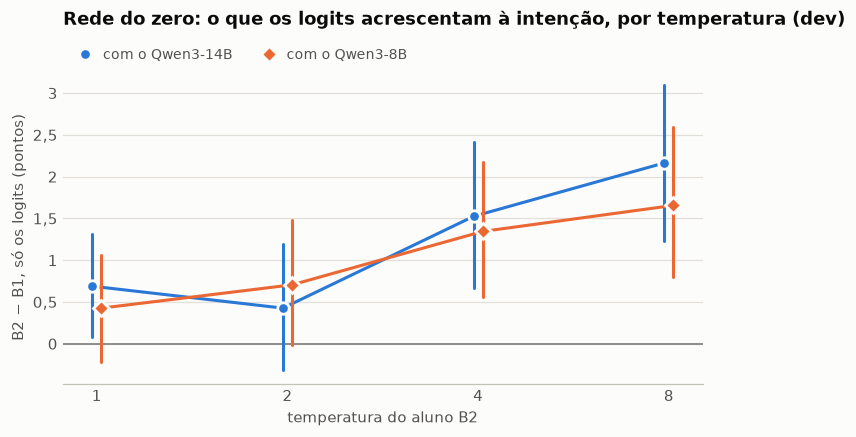

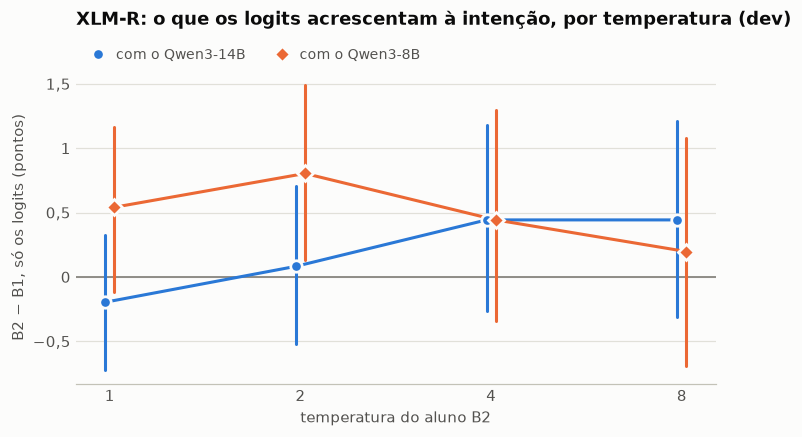

In [5]:
for c in CAMINHOS:
    series = {
        f"com o {quem}": {int(l["temperatura"]): (100 * l["b2_menos_b1_intent_acc"], 100 * l["b2_menos_b1_intent_acc_ic_min"], 100 * l["b2_menos_b1_intent_acc_ic_max"])
                          for _, l in temps[(temps["caminho"] == c) & (temps["professor"] == p)].iterrows()}
        for p, quem in (("novo", NOVO), ("antigo", VELHO))
    }
    fig, ax = visual.curva_com_intervalo(series, f"{CAMINHOS[c]['nome']}: o que os logits acrescentam à intenção, por temperatura (dev)",
                                         "temperatura do aluno B2", "B2 − B1, só os logits (pontos)", niveis=True)
    ax.axhline(0, color=visual.TINTA_SUAVE, linewidth=1.2, zorder=0.6)
    visual.salvar(fig, PASTA, f"temperaturas_{c}")

In [6]:
def sobre_a_temperatura(c):
    nova = temps[(temps["caminho"] == c) & (temps["professor"] == "novo")].set_index("temperatura")
    escolhida, antiga = T_NOVA[c], T_ANTIGA[c]
    empatadas = [int(T) for T in nova.index if T != escolhida and nova.loc[T, "intent_acc"] == nova.loc[escolhida, "intent_acc"]]
    melhores_que = [int(T) for T in nova.index if T != escolhida and nova.loc[T, "escolhida_menos_esta_ic_min"] > 0]
    faixa = 100 * (nova["intent_acc"].max() - nova["intent_acc"].min())
    frase = f"**{CAMINHOS[c]['nome']}: T = {escolhida}**" + (", a mesma do professor antigo." if escolhida == antiga else f"; com o professor antigo era T = {antiga}.")
    if empatadas:
        frase += (f" Em intenção, T = {escolhida} empata exatamente com T = {', '.join(map(str, empatadas))} ({pts(nova.loc[escolhida, 'intent_acc'], 2)}%); "
                  f"o desempate foi pelo exact match ({pts(nova.loc[escolhida, 'exact_match'], 2)}% contra {', '.join(pts(nova.loc[T, 'exact_match'], 2) for T in empatadas)}%).")
    frase += (f" A escolhida é distinguivelmente melhor que T = {', '.join(map(str, melhores_que))}" if melhores_que else " A escolhida não é distinguivelmente melhor que nenhuma das outras")
    frase += f"; entre a melhor e a pior temperatura há {num(faixa)} ponto de intenção."
    if escolhida == max(etapa11b.TEMPERATURAS):
        frase += " É a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor, e a grade não foi ampliada."
    return frase


texto_das_temperaturas = "\n".join(f"- {sobre_a_temperatura(c)}" for c in CAMINHOS)
display(Markdown(texto_das_temperaturas))

- **Rede do zero: T = 8**, a mesma do professor antigo. A escolhida é distinguivelmente melhor que T = 1, 2; entre a melhor e a pior temperatura há 1,7 ponto de intenção. É a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor, e a grade não foi ampliada.
- **XLM-R: T = 8**; com o professor antigo era T = 2. Em intenção, T = 8 empata exatamente com T = 4 (81,44%); o desempate foi pelo exact match (50,83% contra 50,16%). A escolhida não é distinguivelmente melhor que nenhuma das outras; entre a melhor e a pior temperatura há 0,6 ponto de intenção. É a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor, e a grade não foi ampliada.

## 3. Os alunos novos e os antigos

Todos os sistemas das comparações, em `dev` e no teste, contra os rótulos humanos. Valor em % com intervalo de 95%; os sistemas treinados entram com a média das 3 sementes. Cada aluno B2 está na temperatura que a regra escolheu em `dev` com o seu professor.

In [7]:
def ordem_dos_sistemas():
    chaves = ["prof:antigo", "prof:novo", "prof:fechado"]
    for c in CAMINHOS:
        for s in (("B1", "B1s", "B2") if c == "zero" else ("B1", "B2")):
            chaves += [f"{c}:{s}:antigo", f"{c}:{s}:novo"]
        chaves.append(f"{c}:A")
    return chaves


ORDEM = ordem_dos_sistemas()
colunas = [(p, m) for p in ("dev", "test") for m in TRES]
principal = pd.DataFrame({f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})": {nome_do_sistema(chave): valor_com_intervalo(medida(chave, p, m)) for chave in ORDEM} for p, m in colunas})
principal

,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
Qwen3-8B em 4 bits (professor aberto antigo),"77,4 (75,7 a 79,2)","58,0 (55,9 a 60,1)","43,2 (41,0 a 45,3)","77,6 (76,1 a 79,1)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)"
Qwen3-14B (professor aberto novo),"80,6 (79,0 a 82,3)","62,4 (60,4 a 64,6)","49,1 (47,0 a 51,5)","80,0 (78,6 a 81,4)","61,4 (59,6 a 63,1)","49,0 (46,9 a 50,7)"
Claude Haiku 5.5 (professor fechado),"84,1 (82,6 a 85,6)","68,5 (66,5 a 70,5)","54,7 (52,6 a 57,0)","83,5 (82,1 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)"
Rede do zero · Aluno B1 (rótulos do Qwen3-8B),"77,2 (75,6 a 78,8)","60,0 (57,9 a 61,9)","45,2 (43,2 a 47,2)","76,3 (74,9 a 77,7)","57,1 (55,4 a 58,9)","43,6 (41,9 a 45,2)"
Rede do zero · Aluno B1 (rótulos do Qwen3-14B),"79,1 (77,6 a 80,7)","62,6 (60,7 a 64,6)","47,5 (45,6 a 49,5)","77,9 (76,5 a 79,3)","61,4 (59,8 a 63,1)","47,7 (45,9 a 49,3)"
"Rede do zero · Aluno B1 sem suavização (controle, Qwen3-8B)","76,6 (75,0 a 78,3)","59,5 (57,5 a 61,4)","44,3 (42,3 a 46,3)","75,5 (74,0 a 76,9)","57,1 (55,4 a 58,8)","43,3 (41,6 a 45,0)"
"Rede do zero · Aluno B1 sem suavização (controle, Qwen3-14B)","78,3 (76,7 a 79,9)","62,9 (61,1 a 64,9)","47,1 (45,3 a 49,2)","77,3 (75,9 a 78,7)","60,9 (59,2 a 62,5)","47,1 (45,3 a 48,7)"
"Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8)","78,3 (76,7 a 79,9)","60,5 (58,5 a 62,5)","46,9 (44,9 a 49,0)","77,8 (76,3 a 79,3)","58,0 (56,3 a 59,8)","46,0 (44,2 a 47,6)"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8)","80,5 (79,0 a 82,1)","62,2 (60,3 a 64,1)","48,5 (46,4 a 50,5)","78,6 (77,3 a 80,0)","60,4 (58,7 a 62,1)","48,8 (46,9 a 50,4)"
Rede do zero · Aluno A (rótulos do Claude Haiku 5.5),"81,6 (80,1 a 83,1)","67,0 (65,0 a 68,9)","52,0 (50,0 a 54,2)","80,7 (79,4 a 82,0)","64,8 (63,2 a 66,5)","51,2 (49,6 a 52,9)"


PosixPath('/home/danie/project/residencia/entregas/11b_alunos_do_professor_maior/figuras/alunos_no_teste.png')

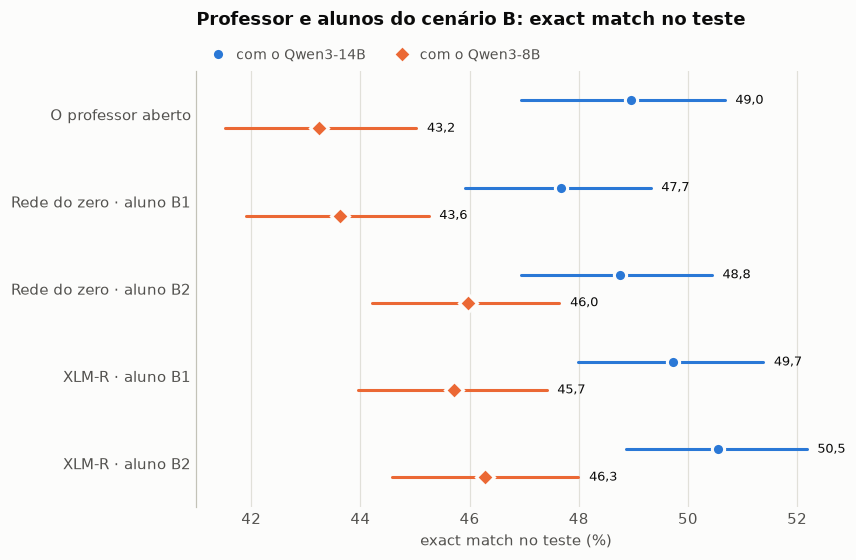

In [8]:
series = {
    f"com o {quem}": {rotulo: tuple(100 * medida(chave.format(p=p), "test")[k] for k in ("valor", "ic_min", "ic_max")) for rotulo, chave in (
        ("O professor aberto", "prof:{p}"), *((f"{CAMINHOS[c]['nome']} · {SIGLAS[s]}", f"{c}:{s}:{{p}}") for c, s in PRINCIPAIS))}
    for p, quem in (("novo", NOVO), ("antigo", VELHO))
}
fig, ax = visual.pontos_com_intervalo(series, "Professor e alunos do cenário B: exact match no teste", "exact match no teste (%)")
visual.salvar(fig, PASTA, "alunos_no_teste")

## 4. O professor melhor faz alunos melhores?

A comparação que responde é pareada: o aluno treinado com o professor novo menos o aluno de mesma receita treinado com o antigo. A leitura principal é o exact match no teste; uma diferença só vale quando o intervalo de 95% não contém zero.

In [9]:
def tabela_de_comparacoes(ids):
    return pd.DataFrame({f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})": {uma(comp, i, p, m)["nome"]: com_intervalo(uma(comp, i, p, m)) for i in ids} for p, m in colunas})


ids_novo_antigo = [id_novo_antigo(c, s) for c in CAMINHOS for s in (("B1", "B1s", "B2") if c == "zero" else ("B1", "B2"))]
ids_mesma_T = [f"mesma_temperatura|{c}:B2:novo@T_antiga|{c}:B2:antigo" for c in CAMINHOS if T_NOVA[c] != T_ANTIGA[c]]
tabela_de_comparacoes([ID_PROFESSORES, *ids_novo_antigo, *ids_mesma_T])

,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
professor novo − professor antigo,"+3,1 (+1,8 a +4,5)","+4,5 (+2,8 a +6,2)","+6,0 (+4,2 a +7,7)","+2,4 (+1,3 a +3,6)","+5,7 (+4,3 a +7,1)","+5,7 (+4,2 a +7,3)"
Rede do zero · aluno B1: com o professor novo − com o antigo,"+1,9 (+0,9 a +2,9)","+2,7 (+1,4 a +4,1)","+2,3 (+0,9 a +3,8)","+1,5 (+0,7 a +2,5)","+4,3 (+3,1 a +5,4)","+4,0 (+2,9 a +5,2)"
Rede do zero · aluno B1 sem suavização: com o professor novo − com o antigo,"+1,7 (+0,7 a +2,8)","+3,5 (+2,2 a +4,8)","+2,9 (+1,4 a +4,4)","+1,8 (+0,8 a +2,7)","+3,8 (+2,7 a +5,0)","+3,7 (+2,5 a +4,9)"
Rede do zero · aluno B2: com o professor novo − com o antigo,"+2,2 (+1,2 a +3,2)","+1,7 (+0,4 a +2,9)","+1,6 (+0,2 a +2,8)","+0,8 (−0,1 a +1,8)","+2,4 (+1,3 a +3,4)","+2,8 (+1,6 a +3,9)"
XLM-R · aluno B1: com o professor novo − com o antigo,"+2,0 (+0,8 a +3,0)","+1,7 (+0,4 a +3,1)","+3,7 (+2,2 a +5,1)","+1,1 (+0,2 a +2,0)","+3,2 (+2,1 a +4,3)","+4,0 (+2,9 a +5,2)"
XLM-R · aluno B2: com o professor novo − com o antigo,"+1,6 (+0,6 a +2,6)","+2,3 (+1,1 a +3,7)","+3,5 (+2,2 a +5,0)","+1,6 (+0,8 a +2,5)","+3,0 (+1,9 a +4,1)","+4,3 (+3,1 a +5,5)"
XLM-R · aluno B2: novo na temperatura do antigo − antigo,"+1,2 (+0,1 a +2,3)","+2,7 (+1,4 a +3,9)","+3,2 (+1,8 a +4,6)","+0,9 (+0,0 a +1,8)","+3,0 (+1,8 a +4,1)","+3,6 (+2,4 a +4,8)"


PosixPath('/home/danie/project/residencia/entregas/11b_alunos_do_professor_maior/figuras/novo_menos_antigo.png')

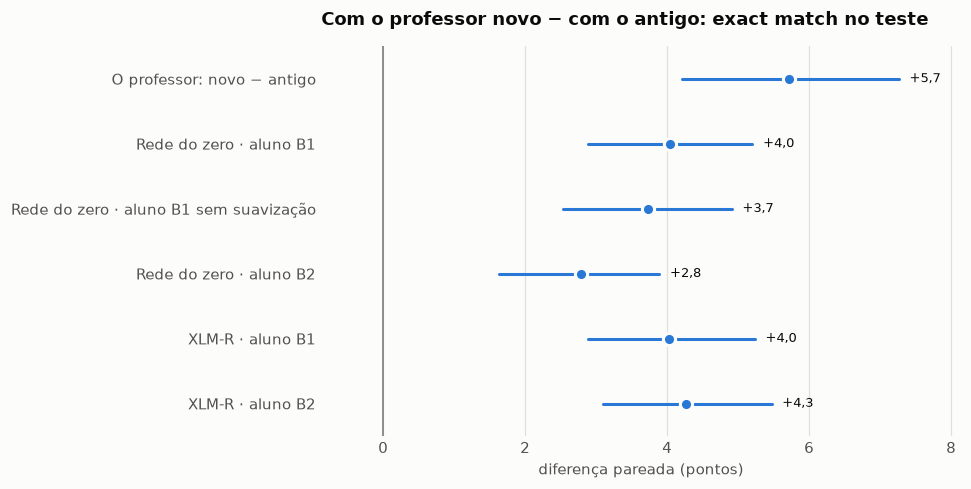

In [10]:
dados = {"O professor: novo − antigo": trio(comparacao(ID_PROFESSORES))}
dados.update({f"{CAMINHOS[c]['nome']} · {SIGLAS[s]}": trio(comparacao(id_novo_antigo(c, s))) for c in CAMINHOS for s in (("B1", "B1s", "B2") if c == "zero" else ("B1", "B2"))})
fig, ax = visual.diferencas_com_intervalo(dados, "Com o professor novo − com o antigo: exact match no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "novo_menos_antigo")

In [11]:
melhorou = {(c, s): comparacao(id_novo_antigo(c, s)) for c, s in PRINCIPAIS}
todos_melhores = all(l["ic_min"] > 0 for l in melhorou.values())
do_professor = comparacao(ID_PROFESSORES)
linhas = [f"- **{CAMINHOS[c]['nome']}, {SIGLAS[s]}:** {com_intervalo(l)} pontos de exact match no teste ({leitura(l)}); em `dev`, {com_intervalo(comparacao(id_novo_antigo(c, s), 'dev'))}." for (c, s), l in melhorou.items()]
controle = comparacao(id_novo_antigo("zero", "B1s"))
linhas.append(f"- O controle da rede do zero (B1 sem suavização) repete o resultado: {com_intervalo(controle)}.")
for c in CAMINHOS:
    if T_NOVA[c] != T_ANTIGA[c]:
        mesma = comparacao(f"mesma_temperatura|{c}:B2:novo@T_antiga|{c}:B2:antigo")
        linhas.append(f"- **Sensibilidade à temperatura ({CAMINHOS[c]['nome']}):** com o B2 novo na temperatura do antigo (T = {T_ANTIGA[c]}), a diferença é de {com_intervalo(mesma)} ({leitura(mesma)}): "
                      + ("a troca de temperatura não explica o ganho." if mesma["ic_min"] > 0 else "com a temperatura igual o ganho já não se distingue de zero."))
    else:
        linhas.append(f"- **{CAMINHOS[c]['nome']}:** a regra escolheu a mesma temperatura (T = {T_NOVA[c]}) com os dois professores; a comparação do B2 já é com a temperatura igual.")
texto_do_ganho = (f"O professor ganhou {com_intervalo(do_professor)} pontos de exact match no teste. " +
                  ("Os quatro alunos ficaram distinguivelmente melhores." if todos_melhores else "Nem todos os alunos ficaram distinguivelmente melhores."))
display(Markdown(texto_do_ganho + "\n\n" + "\n".join(linhas)))

O professor ganhou +5,7 (+4,2 a +7,3) pontos de exact match no teste. Os quatro alunos ficaram distinguivelmente melhores.

- **Rede do zero, aluno B1:** +4,0 (+2,9 a +5,2) pontos de exact match no teste (acima); em `dev`, +2,3 (+0,9 a +3,8).
- **Rede do zero, aluno B2:** +2,8 (+1,6 a +3,9) pontos de exact match no teste (acima); em `dev`, +1,6 (+0,2 a +2,8).
- **XLM-R, aluno B1:** +4,0 (+2,9 a +5,2) pontos de exact match no teste (acima); em `dev`, +3,7 (+2,2 a +5,1).
- **XLM-R, aluno B2:** +4,3 (+3,1 a +5,5) pontos de exact match no teste (acima); em `dev`, +3,5 (+2,2 a +5,0).
- O controle da rede do zero (B1 sem suavização) repete o resultado: +3,7 (+2,5 a +4,9).
- **Rede do zero:** a regra escolheu a mesma temperatura (T = 8) com os dois professores; a comparação do B2 já é com a temperatura igual.
- **Sensibilidade à temperatura (XLM-R):** com o B2 novo na temperatura do antigo (T = 2), a diferença é de +3,6 (+2,4 a +4,8) (acima): a troca de temperatura não explica o ganho.

## 5. Quanto do ganho do professor chega ao aluno

**Repasse** = (aluno novo − aluno antigo) ÷ (professor novo − professor antigo), na mesma métrica e na mesma partição. 100% quer dizer que o aluno ganhou os mesmos pontos que o professor; menos de 100%, que só parte do ganho chegou; mais de 100%, que o aluno ganhou mais do que o professor. O intervalo vem do mesmo bootstrap por enunciado das outras medidas, com os quatro sistemas reamostrados juntos: em cada reamostra calcula-se a razão. A razão só é lida onde o ganho do professor é distinguível de zero.

Ao lado da razão fica a mesma conta em diferença, que não depende de dividir: ganho do aluno − ganho do professor, em pontos.

In [12]:
def linha_do_repasse(c, s, p, m):
    r, d = uma(reps, f"repasse|{c}|{s}", p, m), (uma(difs, f"ganho|{c}|{s}", p, m) if s != "B1s" else None)
    return {
        "Aluno": f"{CAMINHOS[c]['nome']} · {SIGLAS[s]}", "Partição": NOME_DA_PARTICAO[p], "Métrica": CURTA[m],
        "Ganho do aluno": f"{dif(r['ganho_do_aluno'])} ({dif(r['aluno_ic_min'])} a {dif(r['aluno_ic_max'])})",
        "Ganho do professor": f"{dif(r['ganho_do_professor'])} ({dif(r['professor_ic_min'])} a {dif(r['professor_ic_max'])})",
        "Repasse": razao_com_intervalo(r) if r["legivel"] else "não se lê",
        "Aluno − professor, em pontos": com_intervalo(d) if d is not None else "",
    }


alunos_do_repasse = [(c, s) for c in CAMINHOS for s in (("B1", "B1s", "B2") if c == "zero" else ("B1", "B2"))]
quadro_do_repasse = pd.DataFrame([linha_do_repasse(c, s, p, m) for p in ("test", "dev") for m in ("exact_match", "intent_acc", "slot_f1") for c, s in alunos_do_repasse])
quadro_do_repasse[quadro_do_repasse["Métrica"] == "Exact match"].drop(columns="Métrica").set_index(["Partição", "Aluno"])

Ganho do aluno  \
Partição Aluno                                                        
teste    Rede do zero · aluno B1                 +4,0 (+2,9 a +5,2)   
         Rede do zero · aluno B1 sem suavização  +3,7 (+2,5 a +4,9)   
         Rede do zero · aluno B2                 +2,8 (+1,6 a +3,9)   
         XLM-R · aluno B1                        +4,0 (+2,9 a +5,2)   
         XLM-R · aluno B2                        +4,3 (+3,1 a +5,5)   
dev      Rede do zero · aluno B1                 +2,3 (+0,9 a +3,8)   
         Rede do zero · aluno B1 sem suavização  +2,9 (+1,4 a +4,4)   
         Rede do zero · aluno B2                 +1,6 (+0,2 a +2,8)   
         XLM-R · aluno B1                        +3,7 (+2,2 a +5,1)   
         XLM-R · aluno B2                        +3,5 (+2,2 a +5,0)   

                                                 Ganho do professor  \
Partição Aluno                                                        
teste    Rede do zero · aluno B1                 +5,7 (+4,2 a +7,3)   
         Rede do zero · aluno B1 sem suavização  +5,7 (+4,2 a +7,3)   
         Rede do zero · aluno B2                 +5,7 (+4,2 a +7,3)   
         XLM-R · aluno B1                        +5,7 (+4,2 a +7,3)   
         XLM-R · aluno B2                        +5,7 (+4,2 a +7,3)   
dev      Rede do zero · aluno B1                 +6,0 (+4,2 a +7,7)   
         Rede do zero · aluno B1 sem suavização  +6,0 (+4,2 a +7,7)   
         Rede do zero · aluno B2                 +6,0 (+4,2 a +7,7)   
         XLM-R · aluno B1                        +6,0 (+4,2 a +7,7)   
         XLM-R · aluno B2                        +6,0 (+4,2 a +7,7)   

                                                        Repasse  \
Partição Aluno                                                    
teste    Rede do zero · aluno B1                 71% (49 a 101)   
         Rede do zero · aluno B1 sem suavização   65% (43 a 94)   
         Rede do zero · aluno B2                  49% (29 a 72)   
         XLM-R · aluno B1                        70% (48 a 100)   
         XLM-R · aluno B2                        75% (53 a 103)   
dev      Rede do zero · aluno B1                  39% (15 a 66)   
         Rede do zero · aluno B1 sem suavização   48% (25 a 77)   
         Rede do zero · aluno B2                   26% (4 a 49)   
         XLM-R · aluno B1                         62% (38 a 92)   
         XLM-R · aluno B2                         60% (36 a 88)   

                                                Aluno − professor, em pontos  
Partição Aluno                                                                
teste    Rede do zero · aluno B1                          −1,7 (−3,4 a +0,1)  
         Rede do zero · aluno B1 sem suavização                               
         Rede do zero · aluno B2                          −2,9 (−4,6 a −1,3)  
         XLM-R · aluno B1                                 −1,7 (−3,4 a −0,0)  
         XLM-R · aluno B2                                 −1,4 (−3,0 a +0,1)  
dev      Rede do zero · aluno B1                          −3,6 (−5,6 a −1,8)  
         Rede do zero · aluno B1 sem suavização                               
         Rede do zero · aluno B2                          −4,4 (−6,3 a −2,5)  
         XLM-R · aluno B1                                 −2,3 (−4,1 a −0,4)  
         XLM-R · aluno B2                                 −2,4 (−4,3 a −0,6)

PosixPath('/home/danie/project/residencia/entregas/11b_alunos_do_professor_maior/figuras/repasse.png')

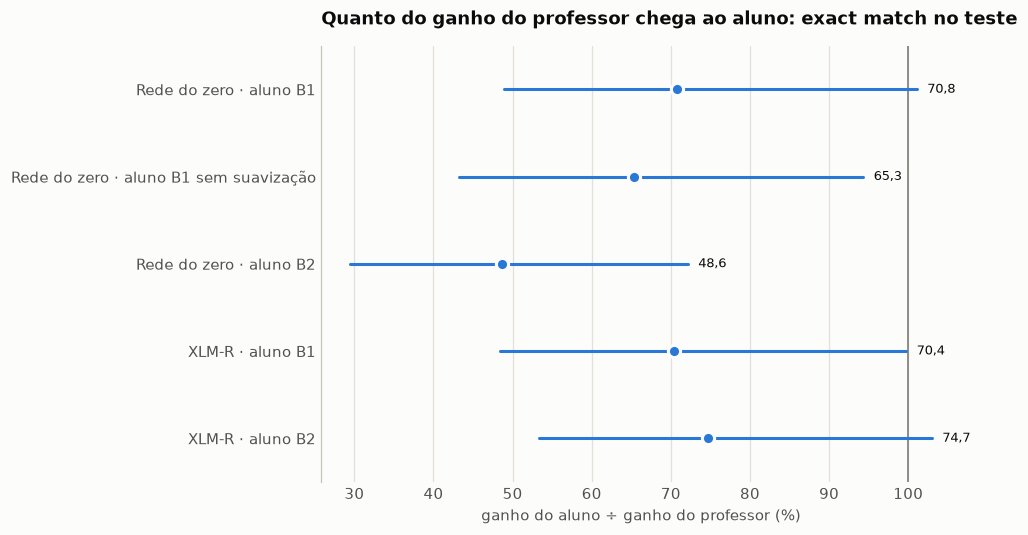

In [13]:
serie = {f"{CAMINHOS[c]['nome']} · {SIGLAS[s]}": tuple(100 * uma(reps, f"repasse|{c}|{s}", "test", "exact_match")[k] for k in ("repasse", "ic_min", "ic_max")) for c, s in alunos_do_repasse}
fig, ax = visual.pontos_com_intervalo({"repasse": serie}, "Quanto do ganho do professor chega ao aluno: exact match no teste", "ganho do aluno ÷ ganho do professor (%)")
ax.axvline(100, color=visual.TINTA_SUAVE, linewidth=1.2, zorder=0.6)
visual.salvar(fig, PASTA, "repasse")

In [14]:
no_teste = {(c, s): uma(reps, f"repasse|{c}|{s}", "test", "exact_match") for c, s in PRINCIPAIS}
em_dev = {(c, s): uma(reps, f"repasse|{c}|{s}", "dev", "exact_match") for c, s in PRINCIPAIS}
menor, maior = min(no_teste.values(), key=lambda r: r["repasse"]), max(no_teste.values(), key=lambda r: r["repasse"])
abaixo_de_tudo = [par for par, r in no_teste.items() if r["ic_max"] < 1]        # o intervalo inteiro abaixo de 100%
claros = [par for par in abaixo_de_tudo if round(100 * no_teste[par]["ic_max"]) < 100]   # e não só por uma fração de ponto
no_limite = [par for par in abaixo_de_tudo if par not in claros]
chegou_algo = all(r["ic_min"] > 0 for r in no_teste.values())
largura_media = float(np.mean([r["ic_max"] - r["ic_min"] for r in no_teste.values()]))
em_pontos = {(c, s): uma(difs, f"ganho|{c}|{s}", "test", "exact_match") for c, s in PRINCIPAIS}
perdeu_em_pontos = [par for par, d in em_pontos.items() if d["ic_max"] < 0]
perdeu_claro = [par for par in perdeu_em_pontos if round(100 * em_pontos[par]["ic_max"], 1) < 0]
perdeu_no_limite = [par for par in perdeu_em_pontos if par not in perdeu_claro]
nomes = lambda pares: ", ".join(f"{SIGLAS[s]} {'da rede do zero' if c == 'zero' else 'do XLM-R'}" for c, s in pares)
texto_do_repasse = (
    f"No teste, em exact match, o repasse vai de {pts(menor['repasse'], 0)}% a {pts(maior['repasse'], 0)}% entre os quatro alunos. "
    + ("Em todos, o intervalo fica acima de zero: alguma parte do ganho chegou. " if chegou_algo else "Em algum deles o intervalo toca o zero. ")
    + f"Os intervalos são largos, {pts(largura_media, 0)} pontos percentuais de largura em média. "
    + (f"O intervalo inteiro fica abaixo de 100% em: {nomes(claros)}" if claros else "Em nenhum dos quatro o intervalo inteiro fica claramente abaixo de 100%")
    + (f"; em {nomes(no_limite)} o limite de cima encosta em 100% ({'; '.join(razao_com_intervalo(no_teste[par]) for par in no_limite)})" if no_limite else "")
    + ("; nos outros o intervalo passa de 100%, e não dá para afirmar que o aluno ganhou menos que o professor. " if len(abaixo_de_tudo) < len(no_teste) else ". ")
    + f"Na conta em pontos (ganho do aluno − ganho do professor), o aluno ganhou distinguivelmente menos que o professor em: {nomes(perdeu_claro) if perdeu_claro else 'nenhum dos quatro'}"
    + (f"; em {nomes(perdeu_no_limite)} o intervalo encosta em zero ({'; '.join(com_intervalo(em_pontos[par]) for par in perdeu_no_limite)})" if perdeu_no_limite else "") + "."
)
linhas = [f"- **{CAMINHOS[c]['nome']}, {SIGLAS[s]}:** {razao_com_intervalo(r)} no teste; {razao_com_intervalo(em_dev[(c, s)])} em `dev`. Em pontos, aluno − professor: {com_intervalo(em_pontos[(c, s)])}." for (c, s), r in no_teste.items()]
display(Markdown(texto_do_repasse + "\n\n" + "\n".join(linhas)))

No teste, em exact match, o repasse vai de 49% a 75% entre os quatro alunos. Em todos, o intervalo fica acima de zero: alguma parte do ganho chegou. Os intervalos são largos, 49 pontos percentuais de largura em média. O intervalo inteiro fica abaixo de 100% em: aluno B2 da rede do zero; em aluno B1 do XLM-R o limite de cima encosta em 100% (70% (48 a 100)); nos outros o intervalo passa de 100%, e não dá para afirmar que o aluno ganhou menos que o professor. Na conta em pontos (ganho do aluno − ganho do professor), o aluno ganhou distinguivelmente menos que o professor em: aluno B2 da rede do zero; em aluno B1 do XLM-R o intervalo encosta em zero (−1,7 (−3,4 a −0,0)).

- **Rede do zero, aluno B1:** 71% (49 a 101) no teste; 39% (15 a 66) em `dev`. Em pontos, aluno − professor: −1,7 (−3,4 a +0,1).
- **Rede do zero, aluno B2:** 49% (29 a 72) no teste; 26% (4 a 49) em `dev`. Em pontos, aluno − professor: −2,9 (−4,6 a −1,3).
- **XLM-R, aluno B1:** 70% (48 a 100) no teste; 62% (38 a 92) em `dev`. Em pontos, aluno − professor: −1,7 (−3,4 a −0,0).
- **XLM-R, aluno B2:** 75% (53 a 103) no teste; 60% (36 a 88) em `dev`. Em pontos, aluno − professor: −1,4 (−3,0 a +0,1).

Nas outras métricas, o repasse é relatado ao lado (teste). Em acurácia de intenção o ganho do professor é menor, e a razão fica mais instável.

In [15]:
quadro_do_repasse[(quadro_do_repasse["Partição"] == "teste") & (quadro_do_repasse["Métrica"] != "Exact match")].drop(columns="Partição").set_index(["Métrica", "Aluno"])

Ganho do aluno  \
Métrica        Aluno                                                        
Intenção       Rede do zero · aluno B1                 +1,5 (+0,7 a +2,5)   
               Rede do zero · aluno B1 sem suavização  +1,8 (+0,8 a +2,7)   
               Rede do zero · aluno B2                 +0,8 (−0,1 a +1,8)   
               XLM-R · aluno B1                        +1,1 (+0,2 a +2,0)   
               XLM-R · aluno B2                        +1,6 (+0,8 a +2,5)   
Entidades (F1) Rede do zero · aluno B1                 +4,3 (+3,1 a +5,4)   
               Rede do zero · aluno B1 sem suavização  +3,8 (+2,7 a +5,0)   
               Rede do zero · aluno B2                 +2,4 (+1,3 a +3,4)   
               XLM-R · aluno B1                        +3,2 (+2,1 a +4,3)   
               XLM-R · aluno B2                        +3,0 (+1,9 a +4,1)   

                                                       Ganho do professor  \
Métrica        Aluno                                                        
Intenção       Rede do zero · aluno B1                 +2,4 (+1,3 a +3,6)   
               Rede do zero · aluno B1 sem suavização  +2,4 (+1,3 a +3,6)   
               Rede do zero · aluno B2                 +2,4 (+1,3 a +3,6)   
               XLM-R · aluno B1                        +2,4 (+1,3 a +3,6)   
               XLM-R · aluno B2                        +2,4 (+1,3 a +3,6)   
Entidades (F1) Rede do zero · aluno B1                 +5,7 (+4,3 a +7,1)   
               Rede do zero · aluno B1 sem suavização  +5,7 (+4,3 a +7,1)   
               Rede do zero · aluno B2                 +5,7 (+4,3 a +7,1)   
               XLM-R · aluno B1                        +5,7 (+4,3 a +7,1)   
               XLM-R · aluno B2                        +5,7 (+4,3 a +7,1)   

                                                              Repasse  \
Métrica        Aluno                                                    
Intenção       Rede do zero · aluno B1                 64% (26 a 126)   
               Rede do zero · aluno B1 sem suavização  73% (34 a 142)   
               Rede do zero · aluno B2                  34% (−3 a 80)   
               XLM-R · aluno B1                          44% (8 a 96)   
               XLM-R · aluno B2                        68% (33 a 131)   
Entidades (F1) Rede do zero · aluno B1                 75% (53 a 104)   
               Rede do zero · aluno B1 sem suavização   67% (45 a 94)   
               Rede do zero · aluno B2                  42% (23 a 64)   
               XLM-R · aluno B1                         56% (36 a 78)   
               XLM-R · aluno B2                         52% (33 a 76)   

                                                      Aluno − professor, em pontos  
Métrica        Aluno                                                                
Intenção       Rede do zero · aluno B1                          −0,9 (−2,2 a +0,4)  
               Rede do zero · aluno B1 sem suavização                               
               Rede do zero · aluno B2                          −1,6 (−2,9 a −0,3)  
               XLM-R · aluno B1                                 −1,3 (−2,6 a −0,1)  
               XLM-R · aluno B2                                 −0,8 (−2,0 a +0,5)  
Entidades (F1) Rede do zero · aluno B1                          −1,5 (−3,1 a +0,2)  
               Rede do zero · aluno B1 sem suavização                               
               Rede do zero · aluno B2                          −3,3 (−5,0 a −1,8)  
               XLM-R · aluno B1                                 −2,5 (−4,1 a −1,1)  
               XLM-R · aluno B2                                 −2,7 (−4,3 a −1,2)

## 6. O que os logits valem com cada professor

O aluno B2 difere do B1 por aprender a intenção das probabilidades do professor, e não só do rótulo. Na rede do zero, o B1 da receita da Etapa 4b tem suavização de rótulos; por isso a comparação limpa é contra o **controle** (o B1 sem suavização), que só difere do B2 nos logits. No XLM-R o B1 já não tem suavização. Os logits só falam de intenção: a leitura principal é a acurácia de intenção no teste.

A última pergunta da etapa é uma diferença de diferenças: (B2 − B1 com o professor novo) − (B2 − B1 com o antigo), com os quatro sistemas reamostrados juntos.

In [16]:
ids_logits = [id_logits(c, p) for c in CAMINHOS for p in ("novo", "antigo")] + [f"logits|zero:B2:{p}|zero:B1:{p}" for p in ("novo", "antigo")]
display(tabela_de_comparacoes(ids_logits))
ids_dd = [f"logits|{c}|B2-{SO_LOGITS[c]}" for c in CAMINHOS] + ["logits|zero|B2-B1"]
pd.DataFrame({f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})": {uma(difs, i, p, m)["nome"]: com_intervalo(uma(difs, i, p, m)) for i in ids_dd} for p, m in colunas})

,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
Rede do zero · professor novo: B2 − B1 sem suavização · só os logits mudam,"+2,2 (+1,2 a +3,1)","−0,8 (−1,7 a +0,1)","+1,3 (+0,2 a +2,4)","+1,4 (+0,6 a +2,1)","−0,5 (−1,2 a +0,3)","+1,7 (+0,8 a +2,6)"
Rede do zero · professor antigo: B2 − B1 sem suavização · só os logits mudam,"+1,7 (+0,8 a +2,6)","+1,0 (+0,0 a +2,1)","+2,6 (+1,6 a +3,7)","+2,3 (+1,4 a +3,1)","+1,0 (+0,1 a +1,8)","+2,7 (+1,7 a +3,7)"
XLM-R · professor novo: B2 − B1 · só os logits mudam,"+0,4 (−0,3 a +1,2)","+0,4 (−0,4 a +1,2)","+0,4 (−0,5 a +1,3)","+0,8 (+0,2 a +1,4)","+0,1 (−0,5 a +0,9)","+0,8 (+0,1 a +1,5)"
XLM-R · professor antigo: B2 − B1 · só os logits mudam,"+0,8 (+0,1 a +1,5)","−0,2 (−0,9 a +0,5)","+0,6 (−0,2 a +1,3)","+0,2 (−0,3 a +0,8)","+0,3 (−0,2 a +0,9)","+0,6 (−0,0 a +1,2)"
Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização,"+1,4 (+0,5 a +2,3)","−0,5 (−1,4 a +0,4)","+1,0 (−0,2 a +2,0)","+0,8 (+0,1 a +1,6)","−1,0 (−1,8 a −0,2)","+1,1 (+0,2 a +2,0)"
Rede do zero · professor antigo: B2 − B1 · entram os logits e sai a suavização,"+1,1 (+0,2 a +2,0)","+0,5 (−0,5 a +1,6)","+1,7 (+0,7 a +2,9)","+1,5 (+0,7 a +2,3)","+0,9 (+0,0 a +1,7)","+2,3 (+1,4 a +3,3)"


,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
Rede do zero · o valor dos logits (só os logits mudam): com o professor novo − com o antigo,"+0,5 (−0,6 a +1,6)","−1,8 (−3,1 a −0,6)","−1,3 (−2,8 a +0,0)","−0,9 (−2,0 a +0,1)","−1,4 (−2,5 a −0,4)","−1,0 (−2,1 a +0,2)"
XLM-R · o valor dos logits (só os logits mudam): com o professor novo − com o antigo,"−0,4 (−1,3 a +0,6)","+0,6 (−0,4 a +1,7)","−0,1 (−1,3 a +1,0)","+0,6 (−0,2 a +1,4)","−0,2 (−1,1 a +0,7)","+0,2 (−0,7 a +1,1)"
Rede do zero · B2 − B1 (entram os logits e sai a suavização): com o professor novo − com o antigo,"+0,3 (−0,7 a +1,4)","−1,0 (−2,3 a +0,2)","−0,8 (−2,2 a +0,6)","−0,7 (−1,7 a +0,3)","−1,9 (−3,0 a −0,8)","−1,3 (−2,4 a −0,1)"


PosixPath('/home/danie/project/residencia/entregas/11b_alunos_do_professor_maior/figuras/logits.png')

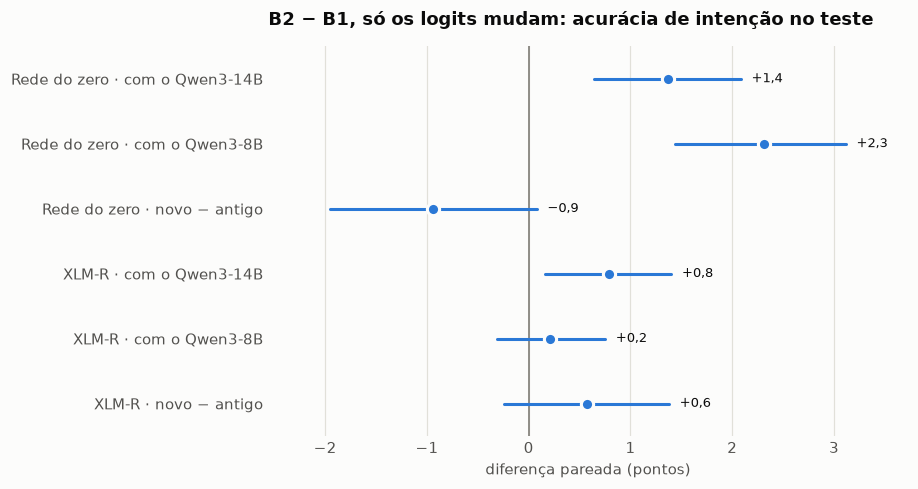

In [17]:
dados = {}
for c in CAMINHOS:
    for p, quem in (("novo", NOVO), ("antigo", VELHO)):
        dados[f"{CAMINHOS[c]['nome']} · com o {quem}"] = trio(comparacao(id_logits(c, p), "test", "intent_acc"))
    dados[f"{CAMINHOS[c]['nome']} · novo − antigo"] = trio(uma(difs, f"logits|{c}|B2-{SO_LOGITS[c]}", "test", "intent_acc"))
fig, ax = visual.diferencas_com_intervalo(dados, "B2 − B1, só os logits mudam: acurácia de intenção no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "logits")

In [18]:
def sobre_os_logits(c):
    novo, antigo = (comparacao(id_logits(c, p), "test", "intent_acc") for p in ("novo", "antigo"))
    dd = uma(difs, f"logits|{c}|B2-{SO_LOGITS[c]}", "test", "intent_acc")
    dd_em_dev = uma(difs, f"logits|{c}|B2-{SO_LOGITS[c]}", "dev", "intent_acc")
    em = lambda p: comparacao(id_logits(c, p), "test", "exact_match")
    vale = lambda l: "valem" if l["ic_min"] > 0 else "não se distinguem de zero"
    mudou = "passaram a valer mais" if dd["ic_min"] > 0 else "passaram a valer menos" if dd["ic_max"] < 0 else "não dá para afirmar que mudaram de valor"
    novo_em_dev, antigo_em_dev = (comparacao(id_logits(c, p), "dev", "intent_acc") for p in ("novo", "antigo"))
    em_dev_e_outra = (f" Em `dev` a leitura de cada professor é outra: {com_intervalo(novo_em_dev)} com o novo ({leitura(novo_em_dev)}) e {com_intervalo(antigo_em_dev)} com o antigo ({leitura(antigo_em_dev)})."
                      if (leitura(novo_em_dev), leitura(antigo_em_dev)) != (leitura(novo), leitura(antigo)) else "")
    return (f"- **{CAMINHOS[c]['nome']}.** Com o {NOVO}, os logits {vale(novo)} em intenção: {com_intervalo(novo)}; com o {VELHO}, {vale(antigo)}: {com_intervalo(antigo)}. "
            f"A diferença das diferenças é de {com_intervalo(dd)} no teste ({com_intervalo(dd_em_dev)} em `dev`): {mudou}. "
            f"Em exact match, B2 − B1 vale {com_intervalo(em('novo'))} com o novo e {com_intervalo(em('antigo'))} com o antigo." + em_dev_e_outra)


dd_principais = {c: uma(difs, f"logits|{c}|B2-{SO_LOGITS[c]}", "test", "intent_acc") for c in CAMINHOS}
valem_mais = [c for c, d in dd_principais.items() if d["ic_min"] > 0]
valem_menos = [c for c, d in dd_principais.items() if d["ic_max"] < 0]
entidades_do_b2 = comparacao(id_logits("zero", "novo"), "test", "slot_f1")
texto_dos_logits = "\n".join(sobre_os_logits(c) for c in CAMINHOS)
texto_dos_logits += (f"\n- Na rede do zero, com o professor novo, o F1 de entidades do B2 fica {leitura(entidades_do_b2)} em relação ao controle ({com_intervalo(entidades_do_b2)}); "
                     f"contra o B1 com suavização, {com_intervalo(comparacao('logits|zero:B2:novo|zero:B1:novo', 'test', 'slot_f1'))}. Os logits são só de intenção: as entidades do B2 vêm dos mesmos rótulos do B1.")
display(Markdown(texto_dos_logits))

- **Rede do zero.** Com o Qwen3-14B, os logits valem em intenção: +1,4 (+0,6 a +2,1); com o Qwen3-8B, valem: +2,3 (+1,4 a +3,1). A diferença das diferenças é de −0,9 (−2,0 a +0,1) no teste (+0,5 (−0,6 a +1,6) em `dev`): não dá para afirmar que mudaram de valor. Em exact match, B2 − B1 vale +1,7 (+0,8 a +2,6) com o novo e +2,7 (+1,7 a +3,7) com o antigo.
- **XLM-R.** Com o Qwen3-14B, os logits valem em intenção: +0,8 (+0,2 a +1,4); com o Qwen3-8B, não se distinguem de zero: +0,2 (−0,3 a +0,8). A diferença das diferenças é de +0,6 (−0,2 a +1,4) no teste (−0,4 (−1,3 a +0,6) em `dev`): não dá para afirmar que mudaram de valor. Em exact match, B2 − B1 vale +0,8 (+0,1 a +1,5) com o novo e +0,6 (−0,0 a +1,2) com o antigo. Em `dev` a leitura de cada professor é outra: +0,4 (−0,3 a +1,2) com o novo (sem diferença distinguível) e +0,8 (+0,1 a +1,5) com o antigo (acima).
- Na rede do zero, com o professor novo, o F1 de entidades do B2 fica sem diferença distinguível em relação ao controle (−0,5 (−1,2 a +0,3)); contra o B1 com suavização, −1,0 (−1,8 a −0,2). Os logits são só de intenção: as entidades do B2 vêm dos mesmos rótulos do B1.

## 7. O aluno ao lado do seu professor e do aluno A

Duas distâncias situam os alunos novos: para o professor que os ensinou (o aluno perde ou ganha ao imitar?) e para o aluno A do mesmo caminho, que aprende do professor fechado.

In [19]:
ids_professor = [id_professor(c, s, p) for c, s in PRINCIPAIS for p in ("novo", "antigo")]
ids_aluno_a = [id_aluno_a(c, s, p) for c, s in PRINCIPAIS for p in ("novo", "antigo")]
display(tabela_de_comparacoes(ids_professor))
tabela_de_comparacoes([*ids_aluno_a, "professores|prof:novo|prof:fechado", "professores|prof:antigo|prof:fechado"])

,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
Rede do zero · aluno B1 − professor novo,"−1,5 (−2,9 a −0,1)","+0,2 (−1,3 a +1,8)","−1,7 (−3,4 a +0,0)","−2,2 (−3,3 a −1,0)","−0,0 (−1,3 a +1,3)","−1,3 (−2,7 a +0,2)"
Rede do zero · aluno B1 − professor antigo,"−0,2 (−1,7 a +1,2)","+2,0 (+0,4 a +3,6)","+2,0 (+0,3 a +3,7)","−1,3 (−2,5 a −0,1)","+1,4 (+0,1 a +2,9)","+0,4 (−1,0 a +1,7)"
Rede do zero · aluno B2 − professor novo,"−0,1 (−1,5 a +1,2)","−0,3 (−1,8 a +1,4)","−0,7 (−2,5 a +1,0)","−1,4 (−2,5 a −0,2)","−1,0 (−2,4 a +0,3)","−0,2 (−1,5 a +1,2)"
Rede do zero · aluno B2 − professor antigo,"+0,9 (−0,6 a +2,3)","+2,5 (+0,9 a +4,2)","+3,7 (+1,9 a +5,5)","+0,2 (−1,0 a +1,3)","+2,3 (+0,8 a +3,9)","+2,7 (+1,2 a +4,3)"
XLM-R · aluno B1 − professor novo,"+0,4 (−0,9 a +1,7)","+0,8 (−0,6 a +2,4)","+1,3 (−0,3 a +2,8)","−0,3 (−1,3 a +0,8)","+0,2 (−0,9 a +1,4)","+0,8 (−0,4 a +2,0)"
XLM-R · aluno B1 − professor antigo,"+1,6 (+0,3 a +2,9)","+3,6 (+2,1 a +5,1)","+3,5 (+1,9 a +5,1)","+1,1 (−0,0 a +2,2)","+2,8 (+1,5 a +4,2)","+2,5 (+1,1 a +3,8)"
XLM-R · aluno B2 − professor novo,"+0,9 (−0,3 a +2,1)","+1,3 (−0,3 a +2,8)","+1,7 (+0,1 a +3,2)","+0,5 (−0,5 a +1,6)","+0,4 (−0,8 a +1,6)","+1,6 (+0,3 a +2,9)"
XLM-R · aluno B2 − professor antigo,"+2,4 (+1,1 a +3,7)","+3,4 (+1,9 a +4,9)","+4,1 (+2,5 a +5,7)","+1,3 (+0,2 a +2,4)","+3,1 (+1,9 a +4,5)","+3,0 (+1,7 a +4,3)"


,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste)
Rede do zero · aluno B1 do professor novo − aluno A,"−2,5 (−3,5 a −1,5)","−4,3 (−5,6 a −3,0)","−4,6 (−6,1 a −3,0)","−2,9 (−3,8 a −1,9)","−3,4 (−4,5 a −2,3)","−3,5 (−4,8 a −2,3)"
Rede do zero · aluno B1 do professor antigo − aluno A,"−4,4 (−5,6 a −3,3)","−7,0 (−8,4 a −5,6)","−6,9 (−8,5 a −5,3)","−4,4 (−5,4 a −3,4)","−7,7 (−8,9 a −6,6)","−7,6 (−8,8 a −6,3)"
Rede do zero · aluno B2 do professor novo − aluno A,"−1,1 (−2,2 a −0,0)","−4,8 (−6,2 a −3,5)","−3,6 (−5,2 a −2,2)","−2,1 (−3,0 a −1,1)","−4,4 (−5,6 a −3,3)","−2,5 (−3,7 a −1,2)"
Rede do zero · aluno B2 do professor antigo − aluno A,"−3,3 (−4,6 a −2,2)","−6,5 (−7,9 a −5,1)","−5,1 (−6,7 a −3,7)","−2,9 (−3,9 a −1,9)","−6,8 (−8,0 a −5,6)","−5,2 (−6,6 a −3,9)"
XLM-R · aluno B1 do professor novo − aluno A,"−2,1 (−3,1 a −1,1)","−4,3 (−5,7 a −3,0)","−4,0 (−5,4 a −2,5)","−2,9 (−3,8 a −2,0)","−3,9 (−5,0 a −2,9)","−4,1 (−5,3 a −2,9)"
XLM-R · aluno B1 do professor antigo − aluno A,"−4,1 (−5,1 a −3,0)","−6,0 (−7,4 a −4,7)","−7,6 (−9,2 a −6,0)","−4,0 (−4,9 a −3,0)","−7,1 (−8,1 a −6,0)","−8,1 (−9,4 a −6,8)"
XLM-R · aluno B2 do professor novo − aluno A,"−1,7 (−2,7 a −0,6)","−3,9 (−5,2 a −2,5)","−3,5 (−5,0 a −2,1)","−2,1 (−3,0 a −1,3)","−3,7 (−4,8 a −2,7)","−3,3 (−4,5 a −2,1)"
XLM-R · aluno B2 do professor antigo − aluno A,"−3,3 (−4,4 a −2,2)","−6,2 (−7,6 a −4,8)","−7,1 (−8,6 a −5,6)","−3,7 (−4,6 a −2,8)","−6,7 (−7,9 a −5,6)","−7,5 (−8,8 a −6,2)"
professor novo − professor fechado,"−3,5 (−4,9 a −2,2)","−6,0 (−7,7 a −4,3)","−5,6 (−7,6 a −3,6)","−3,4 (−4,5 a −2,3)","−4,6 (−6,1 a −3,3)","−5,1 (−6,7 a −3,5)"
professor antigo − professor fechado,"−6,7 (−8,2 a −5,2)","−10,5 (−12,2 a −8,7)","−11,6 (−13,4 a −9,6)","−5,9 (−7,2 a −4,5)","−10,4 (−11,9 a −8,9)","−10,8 (−12,4 a −9,1)"


PosixPath('/home/danie/project/residencia/entregas/11b_alunos_do_professor_maior/figuras/aluno_b_menos_aluno_a.png')

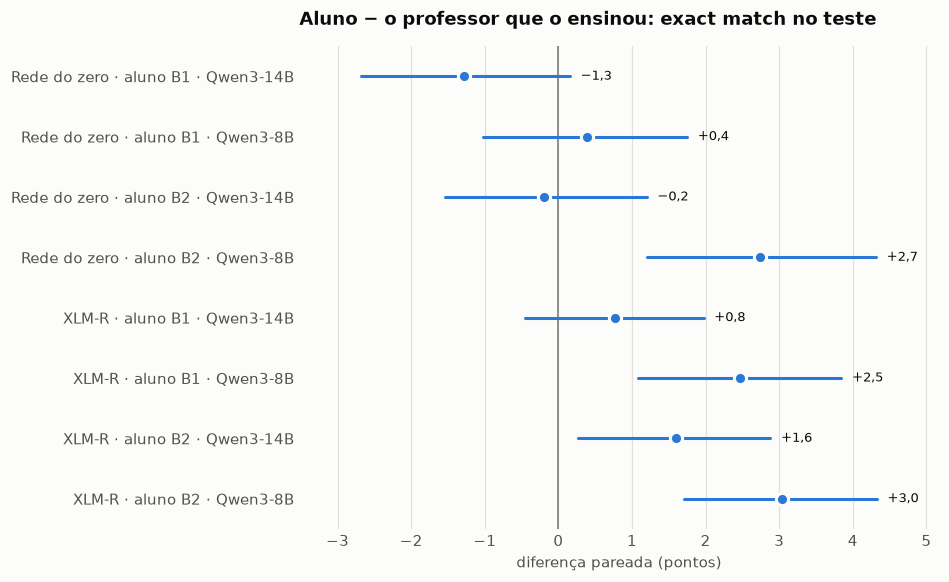

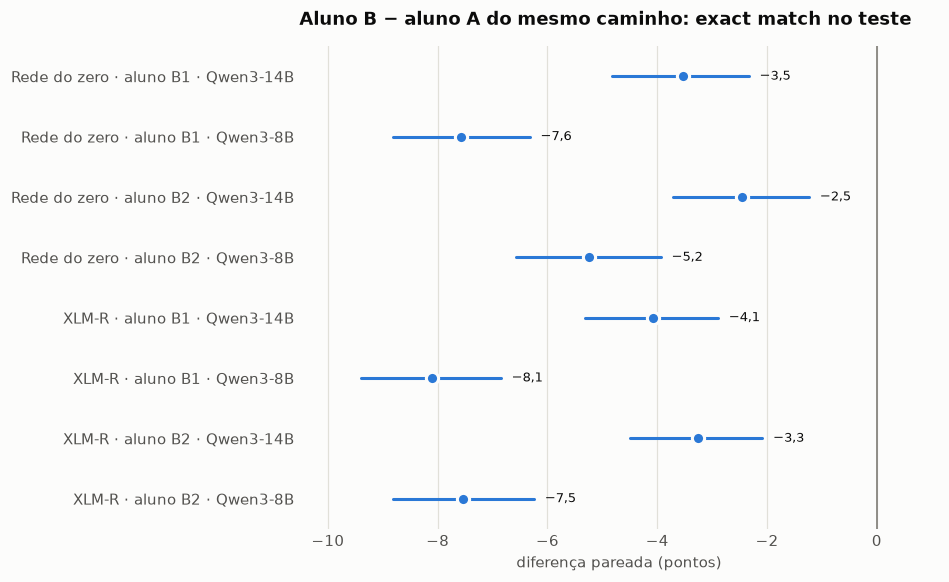

In [20]:
rotulo = lambda c, s, p: f"{CAMINHOS[c]['nome']} · {SIGLAS[s]} · {NOVO if p == 'novo' else VELHO}"
fig, ax = visual.diferencas_com_intervalo({rotulo(c, s, p): trio(comparacao(id_professor(c, s, p))) for c, s in PRINCIPAIS for p in ("novo", "antigo")},
                                          "Aluno − o professor que o ensinou: exact match no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "aluno_menos_professor")
fig, ax = visual.diferencas_com_intervalo({rotulo(c, s, p): trio(comparacao(id_aluno_a(c, s, p))) for c, s in PRINCIPAIS for p in ("novo", "antigo")},
                                          "Aluno B − aluno A do mesmo caminho: exact match no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "aluno_b_menos_aluno_a")

In [21]:
contra_o_novo = {(c, s): comparacao(id_professor(c, s, "novo")) for c, s in PRINCIPAIS}
contra_o_antigo = {(c, s): comparacao(id_professor(c, s, "antigo")) for c, s in PRINCIPAIS}
passam_o_novo = [par for par, l in contra_o_novo.items() if l["ic_min"] > 0]
passavam_o_antigo = [par for par, l in contra_o_antigo.items() if l["ic_min"] > 0]
abaixo_do_novo = [par for par, l in contra_o_novo.items() if l["ic_max"] < 0]
do_a = {(c, s): comparacao(id_aluno_a(c, s, "novo")) for c, s in PRINCIPAIS}
do_a_antes = {(c, s): comparacao(id_aluno_a(c, s, "antigo")) for c, s in PRINCIPAIS}
todos_abaixo_do_a = all(l["ic_max"] < 0 for l in do_a.values())
entre_professores = comparacao("professores|prof:novo|prof:fechado")
texto_do_professor = (
    f"- **Contra o professor.** Em exact match no teste, passam o {NOVO} com intervalo todo acima de zero: {nomes(passam_o_novo) if passam_o_novo else 'nenhum dos quatro alunos'}; "
    f"ficam abaixo: {nomes(abaixo_do_novo) if abaixo_do_novo else 'nenhum'}. Com o {VELHO}, passavam o professor: {nomes(passavam_o_antigo) if passavam_o_antigo else 'nenhum'}. "
    + " ".join(f"{CAMINHOS[c]['nome']}, {SIGLAS[s]}: {com_intervalo(l)} (antes, {com_intervalo(contra_o_antigo[(c, s)])})." for (c, s), l in contra_o_novo.items())
    + f"\n- **Contra o aluno A.** {'Os quatro alunos novos continuam distinguivelmente abaixo do aluno A do seu caminho' if todos_abaixo_do_a else 'Nem todos os alunos novos ficam distinguivelmente abaixo do aluno A'}, "
    f"mas a distância encolheu: " + " ".join(f"{CAMINHOS[c]['nome']}, {SIGLAS[s]}: de {com_intervalo(do_a_antes[(c, s)])} para {com_intervalo(l)}." for (c, s), l in do_a.items())
    + f" Entre os professores, o {NOVO} está a {com_intervalo(entre_professores)} do {FECHADO}."
)
display(Markdown(texto_do_professor))

- **Contra o professor.** Em exact match no teste, passam o Qwen3-14B com intervalo todo acima de zero: aluno B2 do XLM-R; ficam abaixo: nenhum. Com o Qwen3-8B, passavam o professor: aluno B2 da rede do zero, aluno B1 do XLM-R, aluno B2 do XLM-R. Rede do zero, aluno B1: −1,3 (−2,7 a +0,2) (antes, +0,4 (−1,0 a +1,7)). Rede do zero, aluno B2: −0,2 (−1,5 a +1,2) (antes, +2,7 (+1,2 a +4,3)). XLM-R, aluno B1: +0,8 (−0,4 a +2,0) (antes, +2,5 (+1,1 a +3,8)). XLM-R, aluno B2: +1,6 (+0,3 a +2,9) (antes, +3,0 (+1,7 a +4,3)).
- **Contra o aluno A.** Os quatro alunos novos continuam distinguivelmente abaixo do aluno A do seu caminho, mas a distância encolheu: Rede do zero, aluno B1: de −7,6 (−8,8 a −6,3) para −3,5 (−4,8 a −2,3). Rede do zero, aluno B2: de −5,2 (−6,6 a −3,9) para −2,5 (−3,7 a −1,2). XLM-R, aluno B1: de −8,1 (−9,4 a −6,8) para −4,1 (−5,3 a −2,9). XLM-R, aluno B2: de −7,5 (−8,8 a −6,2) para −3,3 (−4,5 a −2,1). Entre os professores, o Qwen3-14B está a −5,1 (−6,7 a −3,5) do Claude Haiku 5.5.

### A fração do caminho entre o piso e o teto (teste)

(aluno − piso) / (teto − piso), como na Etapa 10a: 0 é ficar no piso (os 299 rótulos humanos) e 100% é chegar ao teto (os 11.514 rótulos humanos). Cada caminho usa o seu piso e o seu teto.

In [22]:
def fracao(chave, metrica="exact_match", particao="test"):
    return fracoes[(fracoes["sistema"] == chave) & (fracoes["metrica"] == metrica) & (fracoes["particao"] == particao)].iloc[0]


fracao_com_intervalo = lambda l: f"{pts(l['valor'], 0)}% ({pts(l['ic_min'], 0)} a {pts(l['ic_max'], 0)})"
chaves_da_fracao = [f"{c}:{s}" for c in CAMINHOS for s in ("B1:antigo", "B1:novo", "B2:antigo", "B2:novo", "A")]
quadro_da_fracao = pd.DataFrame({CURTA[m]: {nome_do_sistema(chave): fracao_com_intervalo(fracao(chave, m)) for chave in chaves_da_fracao} for m in TRES})
quadro_da_fracao

,Intenção,Entidades (F1),Exact match
Rede do zero · Aluno B1 (rótulos do Qwen3-8B),82% (79 a 84),50% (46 a 54),55% (51 a 58)
Rede do zero · Aluno B1 (rótulos do Qwen3-14B),85% (83 a 88),63% (59 a 66),64% (61 a 67)
"Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8)",85% (83 a 88),52% (48 a 56),60% (57 a 64)
"Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8)",87% (85 a 90),60% (56 a 63),67% (64 a 70)
Rede do zero · Aluno A (rótulos do Claude Haiku 5.5),92% (90 a 94),73% (70 a 77),73% (70 a 76)
XLM-R · Aluno B1 (rótulos do Qwen3-8B),74% (71 a 78),25% (19 a 31),39% (35 a 43)
XLM-R · Aluno B1 (rótulos do Qwen3-14B),78% (75 a 81),39% (34 a 44),51% (47 a 55)
"XLM-R · Aluno B2 (logits do Qwen3-8B, T = 2)",75% (72 a 78),26% (21 a 32),41% (36 a 44)
"XLM-R · Aluno B2 (logits do Qwen3-14B, T = 8)",80% (77 a 83),40% (35 a 45),53% (49 a 57)
XLM-R · Aluno A (rótulos do Claude Haiku 5.5),87% (84 a 90),56% (51 a 61),63% (59 a 66)


### O aluno imita o professor? (teste)

Em que parte dos pedidos do teste o aluno dá a mesma intenção, e a mesma resposta inteira, que o professor que o ensinou. Depois, na intenção, o que acontece quando um dos dois erra.

In [23]:
no_teste_c = concorda[concorda["particao"] == "test"].set_index("aluno")
igual = lambda l, nome: f"{pts(l[nome])} ({pts(l[nome + '_ic_min'])} a {pts(l[nome + '_ic_max'])})"
quadro_da_concordancia = pd.DataFrame({
    nome_do_sistema(chave): {
        "Intenção igual à do professor": igual(l, "mesma_intencao"), "Resposta inteira igual à do professor": igual(l, "mesma_resposta"),
        "Só o aluno acerta a intenção": f"{pts(l['só o aluno acerta'])}%", "Só o professor acerta a intenção": f"{pts(l['só o professor acerta'])}%",
        "Os dois erram a intenção com a mesma resposta": f"{pts(l['erram com a mesma resposta'])}%",
    } for chave, l in no_teste_c.iterrows()
}).T
quadro_da_concordancia

,Intenção igual à do professor,Resposta inteira igual à do professor,Só o aluno acerta a intenção,Só o professor acerta a intenção,Os dois erram a intenção com a mesma resposta
Rede do zero · Aluno A (rótulos do Claude Haiku 5.5),"83,6 (82,3 a 84,8)","60,7 (59,0 a 62,3)","4,5%","7,2%","7,3%"
XLM-R · Aluno A (rótulos do Claude Haiku 5.5),"86,5 (85,4 a 87,6)","64,2 (62,7 a 65,7)","4,3%","5,1%","8,1%"
Rede do zero · Aluno B1 (rótulos do Qwen3-8B),"79,2 (77,7 a 80,5)","48,8 (47,1 a 50,4)","6,2%","7,5%","9,0%"
Rede do zero · Aluno B1 (rótulos do Qwen3-14B),"81,7 (80,4 a 83,0)","55,6 (53,9 a 57,2)","5,2%","7,3%","9,0%"
"Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8)","80,1 (78,7 a 81,5)","47,6 (45,9 a 49,3)","6,8%","6,6%","9,1%"
"Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8)","82,6 (81,3 a 83,9)","55,4 (53,7 a 57,1)","5,4%","6,7%","9,3%"
XLM-R · Aluno B1 (rótulos do Qwen3-8B),"82,1 (80,9 a 83,4)","53,1 (51,4 a 54,7)","6,4%","5,3%","9,8%"
XLM-R · Aluno B1 (rótulos do Qwen3-14B),"85,3 (84,1 a 86,5)","61,2 (59,6 a 62,7)","4,7%","5,0%","10,2%"
"XLM-R · Aluno B2 (logits do Qwen3-8B, T = 2)","83,2 (82,0 a 84,5)","53,1 (51,4 a 54,8)","6,2%","4,9%","10,4%"
"XLM-R · Aluno B2 (logits do Qwen3-14B, T = 8)","86,4 (85,3 a 87,6)","60,7 (59,0 a 62,2)","4,9%","4,4%","10,8%"


## 8. Onde `dev` e teste discordam

A temperatura foi escolhida em `dev` com os rótulos humanos; o teste só foi aberto depois. As linhas abaixo são as comparações da lista fechada em que o veredito muda de uma partição para a outra (acima, abaixo ou sem diferença distinguível), nas três métricas de leitura.

In [24]:
ambas = comp[comp["metrica"].isin(TRES)].pivot_table(index=["id", "nome", "bloco", "metrica"], columns="particao", values=["diferenca", "ic_min", "ic_max"], sort=False)
ambas.columns = [f"{campo}_{p}" for campo, p in ambas.columns]
ambas = ambas.reset_index()
veredito = lambda l, p: "acima" if l[f"ic_min_{p}"] > 0 else "abaixo" if l[f"ic_max_{p}"] < 0 else "sem diferença distinguível"
texto = lambda l, p: f"{dif(l[f'diferenca_{p}'])} ({dif(l[f'ic_min_{p}'])} a {dif(l[f'ic_max_{p}'])})"
ambas["em_dev"], ambas["no_teste"] = [veredito(l, "dev") for _, l in ambas.iterrows()], [veredito(l, "test") for _, l in ambas.iterrows()]
discordam = ambas[ambas["em_dev"] != ambas["no_teste"]]
invertem = discordam[(discordam["em_dev"] != "sem diferença distinguível") & (discordam["no_teste"] != "sem diferença distinguível")]
quadro_das_discordancias = pd.DataFrame({
    "Comparação": discordam["nome"], "Métrica": discordam["metrica"].map(CURTA), "dev": [texto(l, "dev") for _, l in discordam.iterrows()], "Leitura em dev": discordam["em_dev"],
    "teste": [texto(l, "test") for _, l in discordam.iterrows()], "Leitura no teste": discordam["no_teste"],
}).reset_index(drop=True)
display(Markdown(f"De {len(ambas)} leituras ({ambas['id'].nunique()} comparações × {len(TRES)} métricas), {len(discordam)} mudam de veredito entre `dev` e o teste. "
                 f"Em {len(invertem)} delas o sinal se inverte (acima numa partição, abaixo na outra); nas outras, uma partição distingue e a outra não."))
quadro_das_discordancias

De 93 leituras (31 comparações × 3 métricas), 11 mudam de veredito entre `dev` e o teste. Em 0 delas o sinal se inverte (acima numa partição, abaixo na outra); nas outras, uma partição distingue e a outra não.

,Comparação,Métrica,dev,Leitura em dev,teste,Leitura no teste
0,Rede do zero · aluno B2: com o professor novo − com o antigo,Intenção,"+2,2 (+1,2 a +3,2)",acima,"+0,8 (−0,1 a +1,8)",sem diferença distinguível
1,Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização,Entidades (F1),"−0,5 (−1,4 a +0,4)",sem diferença distinguível,"−1,0 (−1,8 a −0,2)",abaixo
2,Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização,Exact match,"+1,0 (−0,2 a +2,0)",sem diferença distinguível,"+1,1 (+0,2 a +2,0)",acima
3,Rede do zero · aluno B2 − professor novo,Intenção,"−0,1 (−1,5 a +1,2)",sem diferença distinguível,"−1,4 (−2,5 a −0,2)",abaixo
4,Rede do zero · professor antigo: B2 − B1 · entram os logits e sai a suavização,Entidades (F1),"+0,5 (−0,5 a +1,6)",sem diferença distinguível,"+0,9 (+0,0 a +1,7)",acima
5,Rede do zero · aluno B1 − professor antigo,Intenção,"−0,2 (−1,7 a +1,2)",sem diferença distinguível,"−1,3 (−2,5 a −0,1)",abaixo
6,Rede do zero · aluno B1 − professor antigo,Exact match,"+2,0 (+0,3 a +3,7)",acima,"+0,4 (−1,0 a +1,7)",sem diferença distinguível
7,XLM-R · professor novo: B2 − B1 · só os logits mudam,Intenção,"+0,4 (−0,3 a +1,2)",sem diferença distinguível,"+0,8 (+0,2 a +1,4)",acima
8,XLM-R · professor novo: B2 − B1 · só os logits mudam,Exact match,"+0,4 (−0,5 a +1,3)",sem diferença distinguível,"+0,8 (+0,1 a +1,5)",acima
9,XLM-R · professor antigo: B2 − B1 · só os logits mudam,Intenção,"+0,8 (+0,1 a +1,5)",acima,"+0,2 (−0,3 a +0,8)",sem diferença distinguível


In [25]:
principais_que_discordam = discordam[discordam["id"].isin([id_novo_antigo(c, s) for c, s in PRINCIPAIS]) & (discordam["metrica"] == "exact_match")]
logits_que_discordam = discordam[discordam["id"].isin([id_logits(c, p) for c in CAMINHOS for p in ("novo", "antigo")]) & (discordam["metrica"] == "intent_acc")]
repasse_dev_teste = [(c, s, uma(reps, f"repasse|{c}|{s}", "dev", "exact_match"), uma(reps, f"repasse|{c}|{s}", "test", "exact_match")) for c, s in PRINCIPAIS]
texto_das_discordancias = (
    f"- **Novo − antigo, em exact match:** {'as quatro comparações principais têm o mesmo veredito em dev e no teste' if principais_que_discordam.empty else f'{len(principais_que_discordam)} das quatro comparações principais mudam de veredito'}.\n"
    f"- **Logits, em intenção:** {len(logits_que_discordam)} das 4 comparações 'só os logits mudam' mudam de veredito"
    + ("" if logits_que_discordam.empty else ": " + "; ".join(f"{l['nome']} ({texto(l, 'dev')} em dev, {texto(l, 'test')} no teste)" for _, l in logits_que_discordam.iterrows())) + ".\n"
    f"- **Repasse em exact match:** " + "; ".join(f"{CAMINHOS[c]['nome']}, {SIGLAS[s]}: {pts(d['repasse'], 0)}% em dev e {pts(t['repasse'], 0)}% no teste" for c, s, d, t in repasse_dev_teste)
    + ". O ganho do professor é quase o mesmo nas duas partições; o que oscila é o ganho do aluno."
)
display(Markdown(texto_das_discordancias))

- **Novo − antigo, em exact match:** as quatro comparações principais têm o mesmo veredito em dev e no teste.
- **Logits, em intenção:** 2 das 4 comparações 'só os logits mudam' mudam de veredito: XLM-R · professor novo: B2 − B1 · só os logits mudam (+0,4 (−0,3 a +1,2) em dev, +0,8 (+0,2 a +1,4) no teste); XLM-R · professor antigo: B2 − B1 · só os logits mudam (+0,8 (+0,1 a +1,5) em dev, +0,2 (−0,3 a +0,8) no teste).
- **Repasse em exact match:** Rede do zero, aluno B1: 39% em dev e 71% no teste; Rede do zero, aluno B2: 26% em dev e 49% no teste; XLM-R, aluno B1: 62% em dev e 70% no teste; XLM-R, aluno B2: 60% em dev e 75% no teste. O ganho do professor é quase o mesmo nas duas partições; o que oscila é o ganho do aluno.

## 9. Conferência com as etapas anteriores e custo

Os alunos antigos não foram treinados de novo: as respostas deles vêm das entregas das Etapas 4b, 6 e 10a. As comparações entre eles que aquelas etapas já tinham gravado foram refeitas aqui, das mesmas respostas, e postas ao lado do número gravado. Se um número não fechasse, apareceria nesta tabela.

In [26]:
resumo_da_conferencia = conf.groupby(["etapa_de_origem", "nome_na_origem"], sort=False).agg(leituras=("fecha", "size"), fecham=("fecha", "sum"), maior_distancia=("maior_distancia", "max")).reset_index()
display(resumo_da_conferencia.rename(columns={"etapa_de_origem": "Etapa de origem", "nome_na_origem": "Comparação, como a origem a chama", "leituras": "Leituras (partição × métrica)",
                                              "fecham": "Fecham", "maior_distancia": "Maior distância"}).set_index(["Etapa de origem", "Comparação, como a origem a chama"]))
intactas = etapa11b.conferir_intactas(PROFESSOR)
intactas

Leituras (partição × métrica)  \
Etapa de origem            Comparação, como a origem a chama                                                        
06_destilacao              Aluno B2 − aluno B1 sem suavização                                                   8   
                           Aluno B2 − aluno B1                                                                  8   
                           Aluno B1 − professor aberto                                                          8   
                           Aluno B2 − professor aberto                                                          8   
                           Aluno A − aluno B1                                                                   8   
10a_encoder                Aluno B2 − aluno B1                                                                  8   
                           Aluno B1 − professor aberto                                                          8   
                           Aluno B2 − professor aberto                                                          8   
11a_professor_aberto_maior qwen3_14b__fp16__colab_a100 − qwen3_8b__nf4__local_3080                              8   
                           qwen3_14b__fp16__colab_a100 − claude                                                 8   
                           qwen3_8b__nf4__local_3080 − claude                                                   8   

                                                                                    Fecham  \
Etapa de origem            Comparação, como a origem a chama                                 
06_destilacao              Aluno B2 − aluno B1 sem suavização                            8   
                           Aluno B2 − aluno B1                                           8   
                           Aluno B1 − professor aberto                                   8   
                           Aluno B2 − professor aberto                                   8   
                           Aluno A − aluno B1                                            8   
10a_encoder                Aluno B2 − aluno B1                                           8   
                           Aluno B1 − professor aberto                                   8   
                           Aluno B2 − professor aberto                                   8   
11a_professor_aberto_maior qwen3_14b__fp16__colab_a100 − qwen3_8b__nf4__local_3080       8   
                           qwen3_14b__fp16__colab_a100 − claude                          8   
                           qwen3_8b__nf4__local_3080 − claude                            8   

                                                                                    Maior distância  
Etapa de origem            Comparação, como a origem a chama                                         
06_destilacao              Aluno B2 − aluno B1 sem suavização                          0.000000e+00  
                           Aluno B2 − aluno B1                                         0.000000e+00  
                           Aluno B1 − professor aberto                                 0.000000e+00  
                           Aluno B2 − professor aberto                                 0.000000e+00  
                           Aluno A − aluno B1                                          2.081668e-17  
10a_encoder                Aluno B2 − aluno B1                                         0.000000e+00  
                           Aluno B1 − professor aberto                                 0.000000e+00  
                           Aluno B2 − professor aberto                                 0.000000e+00  
11a_professor_aberto_maior qwen3_14b__fp16__colab_a100 − qwen3_8b__nf4__local_3080     0.000000e+00  
                           qwen3_14b__fp16__colab_a100 − claude                        0.000000e+00  
                           qwen3_8b__nf4__local_3080 − claude                          0.000000e+00

,pasta,impressao_tirada_em,arquivos_antes,arquivos_hoje,iguais,novos,sumiram
0,data/execucoes/06_destilacao/,2026-11-18 21:55:35 -0300,144,144,144,0,0
1,data/execucoes/10a_encoder/,2026-11-18 21:55:35 -0300,303,303,303,0,0
2,entregas/06_destilacao/,2026-11-18 21:55:35 -0300,116,116,116,0,0
3,entregas/10a_encoder/,2026-11-18 21:55:35 -0300,154,154,154,0,0


In [27]:
tempo = treinos.groupby("caminho", sort=False).agg(execucoes=("semente", "size"), minutos=("segundos_de_treino", lambda s: s.sum() / 60), por_epoca=("segundos_por_epoca", "mean"), vram=("pico_de_vram_gb", "max"))
na_10a = json.loads((ENTREGAS / "10a_encoder" / "custo.json").read_text(encoding="utf-8"))["treino"]["segundos_por_epoca"]   # o mesmo ajuste fino, medido na Etapa 10a
texto_do_custo = (
    f"- A rodada levou {num(registro['minutos'], 0)} minutos de relógio para {registro['prontas']} treinos: a rede do zero com {CAMINHOS['zero']['processos']} de cada vez, depois o XLM-R em fila.\n"
    f"- Rede do zero: {num(tempo.loc['zero', 'por_epoca'])} s por época por treino, com {CAMINHOS['zero']['processos']} treinos juntos na placa. "
    f"XLM-R: {num(tempo.loc['xlmr', 'por_epoca'])} s por época, com pico de {num(tempo.loc['xlmr', 'vram'])} GB na placa; na Etapa 10a o mesmo treino levava {num(na_10a)} s. "
    "A causa provável é a placa dividida com outros programas da máquina, vistos no `nvidia-smi` antes do lançamento; a rodada não mediu isso. O resultado de um treino não depende do tempo que ele leva.\n"
    f"- O código do pacote ficou igual do começo ao fim da rodada: {'sim' if registro['codigo_igual_do_inicio_ao_fim'] else 'NÃO: ' + ', '.join(registro['codigo_alterado_durante_a_rodada'])}. A cópia do código com que os treinos rodaram está no cache da etapa."
)
display(Markdown(texto_do_custo))

- A rodada levou 92 minutos de relógio para 33 treinos: a rede do zero com 7 de cada vez, depois o XLM-R em fila.
- Rede do zero: 8,4 s por época por treino, com 7 treinos juntos na placa. XLM-R: 22,3 s por época, com pico de 2,8 GB na placa; na Etapa 10a o mesmo treino levava 11,7 s. A causa provável é a placa dividida com outros programas da máquina, vistos no `nvidia-smi` antes do lançamento; a rodada não mediu isso. O resultado de um treino não depende do tempo que ele leva.
- O código do pacote ficou igual do começo ao fim da rodada: sim. A cópia do código com que os treinos rodaram está no cache da etapa.

## 10. O que os artigos sustentam

Cada referência foi buscada na API do arXiv; a coluna "na fonte" diz se o identificador devolveu o título e o primeiro autor que a etapa cita. Só o **resumo** de cada artigo foi lido. A última coluna diz o que o resumo sustenta nesta etapa e o que ele não cobre.

In [28]:
artigos = etapa11b.quadro_de_artigos()
todas_conferidas = bool((artigos["na_fonte"] == "conferida").all())
artigos[["quem", "titulo_na_fonte", "onde", "publicado_na_fonte", "na_fonte", "tecnica", "o_resumo_sustenta", "o_que_o_resumo_diz"]].rename(columns={
    "quem": "Quem", "titulo_na_fonte": "Título na fonte", "onde": "Onde", "publicado_na_fonte": "Publicado", "na_fonte": "Na fonte", "tecnica": "Para que serve aqui",
    "o_resumo_sustenta": "O resumo sustenta", "o_que_o_resumo_diz": "O que o resumo diz, e o que não cobre"}).set_index("Quem")

,Título na fonte,Onde,Publicado,Na fonte,Para que serve aqui,O resumo sustenta,"O que o resumo diz, e o que não cobre"
Quem,,,,,,,
"Hinton, Vinyals & Dean",Distilling the Knowledge in a Neural Network,arXiv 1503.02531,2015-03-09,conferida,A perda do aluno B2: os logits do professor amolecidos por uma temperatura,em parte,"o resumo fala em destilar um conjunto de modelos num modelo só; a temperatura, os alvos suaves e o fator T² estão no corpo do artigo, que não foi relido aqui (a perda do projeto tem teste próprio ..."
Cho & Hariharan,On the Efficacy of Knowledge Distillation,arXiv 1910.01348,2019-10-03,conferida,"Um professor mais exato não faz, por si só, um aluno melhor",em parte,"o resumo diz que professores mais exatos muitas vezes não são bons professores e que modelos maiores não costumam ensinar melhor, por diferença de capacidade. Sustenta a pergunta (o ganho do profe..."
Mirzadeh et al.,Improved Knowledge Distillation via Teacher Assistant,arXiv 1902.03393,2019-02-09,conferida,A distância de tamanho entre professor e aluno atrapalha a destilação,em parte,"o resumo diz que o aluno piora quando a distância para o professor é grande e que um aluno fixo não aproveita um professor arbitrariamente grande; experimentos em CIFAR-10, CIFAR-100 e ImageNet, c..."
Menon et al.,Why distillation helps: a statistical perspective,arXiv 2005.10419,2020-05-21,conferida,O que os logits valem depende de quão bem aproximam as probabilidades de cada classe,em parte,o resumo diz que o professor estima as probabilidades de classe de Bayes e que o aluno ganha com um conhecimento aproximado delas (um compromisso entre viés e variância). Sustenta que o valor dos ...
Yuan et al.,Revisiting Knowledge Distillation via Label Smoothing Regularization,arXiv 1909.11723,2019-09-25,conferida,"Parte do ganho dos alvos suaves é regularização, como a suavização de rótulos (o controle do B2)",em parte,o resumo diz que a destilação é uma suavização de rótulos aprendida e que até um professor mal treinado melhora o aluno. Sustenta o controle desta etapa (separar os logits da suavização); os exper...
Stanton et al.,Does Knowledge Distillation Really Work?,arXiv 2106.05945,2021-06-10,conferida,Imitar o professor e acertar a tarefa são medidas diferentes (aluno − professor e concordância),em parte,"o resumo diz que sobra uma distância grande entre as previsões do professor e do aluno, e que imitar melhor nem sempre generaliza melhor. Sustenta medir a concordância com o professor à parte da q..."
Furlanello et al.,Born Again Neural Networks,arXiv 1805.04770,2018-05-12,conferida,Um aluno pode passar o seu professor,em parte,"o resumo diz que alunos com a mesma arquitetura do professor o superam, em visão e em modelagem de linguagem. Sustenta que um aluno passar o professor é um fenômeno conhecido; aqui o aluno é muito..."


Dois limites saem daí e valem para a leitura desta etapa:

- **Cho & Hariharan** e **Mirzadeh et al.** sustentam a *pergunta*: não é garantido que um professor melhor faça um aluno melhor, e um aluno pequeno pode não aproveitar um professor muito maior. Eles não sustentam a *resposta* daqui. Lá o professor é uma rede treinada na mesma tarefa, com os mesmos dados do aluno (em Mirzadeh et al., redes de visão); aqui é uma LLM que rotula com poucos exemplos no prompt, e o aluno nunca vê um rótulo humano. O que esta etapa mede é um degrau só (de 8 para 14 bilhões de parâmetros), em que o professor maior também erra menos; ela não separa "maior" de "mais exato".
- Os artigos falam de **logits de um professor treinado na tarefa**. Os logits daqui são as probabilidades que uma LLM dá às 60 intenções no próximo token: se eles valem mais ou menos com um professor maior é uma pergunta empírica, que os resumos lidos não respondem.

## 11. Entrega

`etapa11b.entregar` monta a pasta de entrega a partir do cache: as tabelas, as regras, a decisão, os sistemas declarados para o comparativo, as respostas de cada treino e os modelos dos alunos B1 e B2 (na temperatura escolhida), que entram por link físico e não ocupam o disco duas vezes.

In [29]:
destino = etapa11b.entregar(PROFESSOR)
decisao = json.loads((PASTA / "decisao.json").read_text(encoding="utf-8"))
declarados = json.loads((PASTA / "sistemas.json").read_text(encoding="utf-8"))
resultados = pd.read_csv(PASTA / "resultados.csv")
display(Markdown(f"Temperatura do B2: {decisao['temperatura_do_b2']}. Pela regra da Etapa 6, quem representa o cenário B: "
                 + "; ".join(f"{CAMINHOS[c]['nome']}: {representa[c]['representa']}" for c in CAMINHOS) + f". Sistemas declarados para o comparativo: {len(declarados['sistemas'])}."))
resultados[["sistema", "particao", "sementes", "intent_acc", "slot_f1", "exact_match", "parametros", "bytes"]]

Temperatura do B2: {'zero': 8, 'xlmr': 8}. Pela regra da Etapa 6, quem representa o cenário B: Rede do zero: B2; XLM-R: B1. Sistemas declarados para o comparativo: 4.

,sistema,particao,sementes,intent_acc,slot_f1,exact_match,parametros,bytes
0,Rede do zero · Aluno B1 (rótulos do Qwen3-14B),dev,3,0.790949,0.626477,0.474832,4895834,19921914
1,Rede do zero · Aluno B1 sem suavização de rótulos (controle do B2; rótulos do Qwen3-14B),dev,3,0.783243,0.629419,0.471389,4895834,19921914
2,"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 1)",dev,3,0.790130,0.627413,0.476799,4895834,19921914
3,"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 2)",dev,3,0.787506,0.627324,0.470405,4895834,19921914
4,"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 4)",dev,3,0.798492,0.625647,0.481062,4895834,19921914
5,"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 8)",dev,3,0.804886,0.621553,0.484506,4895834,19921914
6,XLM-R · Aluno B1 (rótulos do Qwen3-14B),dev,3,0.809969,0.632515,0.504181,277584555,1127466166
7,"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 1)",dev,3,0.808001,0.637287,0.502213,277584555,1127466166
8,"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 2)",dev,3,0.810789,0.639990,0.504837,277584555,1127466166
9,"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 4)",dev,3,0.814396,0.631227,0.501558,277584555,1127466166


### Os modelos entregues respondem como os que foram medidos?

Cada modelo da entrega (semente 0) é relido do disco, na CPU, e responde de novo ao teste: a rede do zero, ao teste inteiro; o XLM-R, aos 300 primeiros pedidos. As respostas são comparadas com as que a etapa mediu.

In [30]:
from especialista.modelos.diet import SistemaDiet
from especialista.modelos.encoder import SistemaEncoder

relidos = {}
for c in CAMINHOS:
    for sigla in etapa11b.ENTREGUES:
        aluno = decisao["alunos"][c][sigla]
        pasta = RAIZ / aluno["pastas_por_semente"]["0"]
        pedidos = list(teste["utt"]) if c == "zero" else list(teste["utt"])[:300]
        sistema = (SistemaDiet if c == "zero" else SistemaEncoder).carregar(pasta, "cpu")
        medidas_antes = carregar_previsoes(PASTA / "previsoes" / f"{aluno['variante']}_semente_0_test.parquet")[1][:len(pedidos)]
        relidos[aluno["nome"]] = {"pedidos": len(pedidos), "iguais": sum(a == b for a, b in zip(sistema.prever(pedidos), medidas_antes)), "link físico": (pasta / "config.json").stat().st_nlink > 1}
relidos = pd.DataFrame(relidos).T
relidos

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4497.85it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4217.34it/s]

,pedidos,iguais,link físico
Rede do zero · Aluno B1 (rótulos do Qwen3-14B),2974,2974,True
"Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 8)",2974,2974,True
XLM-R · Aluno B1 (rótulos do Qwen3-14B),300,300,True
"XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 8)",300,300,True


### Critério de pronto

In [31]:
from especialista.experimentos import etapa9, etapa10d

metas = {(c, a, s): etapa11b.carregar(c, a, s, PROFESSOR)["meta"] for c, a, s in etapa11b.grade()}
completa = lambda c, d: (etapa11b._classes(c)[0](**d["config"]).como_dict(), etapa11b._classes(c)[1](**d["receita"]).como_dict())
mesmas_receitas = all(igual is True for igual in regras["receitas_iguais_as_antigas"]["resultado"].values()) and all(
    (m["config"], m["receita"]) == completa(c, regras["variantes"][m["variante"]]) for (c, a, s), m in metas.items())
primeiro_treino = min((etapa11b.pasta_da_execucao(c, a, s, PROFESSOR) / "meta.json").stat().st_mtime for c, a, s in metas)
regras_antes = regras["escritas_em"] < registro["iniciada_em"] and (RODADA / "regras.json").stat().st_mtime < primeiro_treino

gabarito_dev = ouro(dev)
pela_regra = all(etapa6.escolher_temperatura(gabarito_dev, {T: etapa11b.previsoes(c, etapa6.variante_do_b2(T), "dev", PROFESSOR) for T in etapa11b.TEMPERATURAS})[0] == T_NOVA[c] for c in CAMINHOS)
com_teste = {c: {a for a in etapa11b.ALUNOS[c] if all((etapa11b.pasta_da_execucao(c, a, s, PROFESSOR) / "previsoes_test.parquet").exists() for s in etapa11b.SEMENTES)} for c in CAMINHOS}
so_os_previstos = all(com_teste[c] == set(decididas[c]["abertas_no_teste"]) for c in CAMINHOS)

previstas = {l["id"] for l in regras["comparacoes"] if l["bloco"] != "mesma_temperatura" or T_NOVA[l["caminho"]] != T_ANTIGA[l["caminho"]]}
lista_inteira = all(set(t[t["particao"] == p]["id"]) == esperado for p in ("dev", "test") for t, esperado in (
    (comp, previstas), (difs, {l["id"] for l in regras["diferencas_de_diferencas"]}), (reps, {l["id"] for l in regras["repasses"]})))

_, fichas, _ = etapa10d.fichas_declaradas(ENTREGAS)
novas = {chave: ficha for chave, ficha in fichas.items() if ficha["declarado_em"].startswith(f"entregas/{etapa11b.ETAPA}/")}
na_tabela = etapa9.tabela_final(novas, entregas=ENTREGAS)      # indexada pela chave do sistema
declarados_ok = (set(novas) == set(declarados["sistemas"]) and all(arquivo.exists() for f in novas.values() for lista in f["previsoes"].values() for arquivo in lista)
                 and all(f["professor"] in fichas for f in novas.values())
                 and all(abs(na_tabela.loc[chave, "exact_match"] - resultados[(resultados["variante"] == f["variante"]) & (resultados["particao"] == "test")]["exact_match"].iloc[0]) < 1e-12 for chave, f in novas.items()))

pronto = pd.Series({
    f"Regras gravadas antes do primeiro treino ({regras['escritas_em'][11:16]} contra {registro['iniciada_em'][11:16]})": bool(regras_antes),
    f"As {len(metas)} execuções estão prontas, 3 sementes por variante, sem erro na rodada": len(metas) == regras["execucoes"] == registro["prontas"] and not registro["erros"],
    "Toda execução leu do professor novo os rótulos do treino, os de dev e, no B2, os logits": do_professor_novo and all(m["origem"]["professor"] == PROFESSOR for m in metas.values()),
    "A configuração e a receita de cada variante são as do aluno antigo de mesmo nome": bool(mesmas_receitas),
    "Nenhum rótulo humano entrou no treino nem na parada dos alunos": sem_rotulo_humano,
    "A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos": bool(pela_regra and so_os_previstos),
    f"Toda comparação da lista fechada está calculada em dev e no teste ({len(previstas)} diferenças, {difs['id'].nunique()} diferenças de diferenças, {reps['id'].nunique()} repasses)": bool(lista_inteira),
    f"As comparações dos alunos antigos, refeitas aqui, fecham com as entregues ({int(conf['fecha'].sum())} de {len(conf)} leituras)": bool(conf["fecha"].all()),
    "Nada no cache e na entrega das Etapas 6 e 10a mudou desde antes do primeiro treino": bool((intactas["iguais"] == intactas["arquivos_antes"]).all() and (intactas["novos"] + intactas["sumiram"]).sum() == 0),
    "O código do pacote não mudou durante a rodada": bool(registro["codigo_igual_do_inicio_ao_fim"]),
    "Os modelos entregues, relidos do disco na CPU, repetem as respostas medidas no teste": bool((relidos["iguais"] == relidos["pedidos"]).all()),
    f"Os {len(novas)} sistemas declarados entram na tabela do comparativo com o número desta etapa": bool(declarados_ok),
    "Cada referência foi conferida na fonte": todas_conferidas,
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Regras gravadas antes do primeiro treino (22:04 contra 22:20),sim
"As 33 execuções estão prontas, 3 sementes por variante, sem erro na rodada",sim
"Toda execução leu do professor novo os rótulos do treino, os de dev e, no B2, os logits",sim
A configuração e a receita de cada variante são as do aluno antigo de mesmo nome,sim
Nenhum rótulo humano entrou no treino nem na parada dos alunos,sim
"A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos",sim
"Toda comparação da lista fechada está calculada em dev e no teste (31 diferenças, 7 diferenças de diferenças, 5 repasses)",sim
"As comparações dos alunos antigos, refeitas aqui, fecham com as entregues (88 de 88 leituras)",sim
Nada no cache e na entrega das Etapas 6 e 10a mudou desde antes do primeiro treino,sim
O código do pacote não mudou durante a rodada,sim


## 12. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/11b_alunos_do_professor_maior/RESUMO.md`.

In [32]:
tres_do_teste = lambda chave: " / ".join(pts(medida(chave, "test", m)["valor"]) for m in TRES)
ganhos = "; ".join(f"{SIGLAS[s]} {'da rede do zero' if c == 'zero' else 'do XLM-R'}, {com_intervalo(l)}" for (c, s), l in melhorou.items())
repasses_do_teste = "; ".join(f"{SIGLAS[s]} {'da rede do zero' if c == 'zero' else 'do XLM-R'}, {razao_com_intervalo(r)}" for (c, s), r in no_teste.items())
veredito_dos_logits = ("Passaram a valer mais nos dois caminhos." if len(valem_mais) == len(CAMINHOS) else "Não dá para afirmar que passaram a valer mais com o professor novo." if not valem_mais and not valem_menos
                       else "Só em parte: " + "; ".join(f"{CAMINHOS[c]['nome']}: {'mais' if c in valem_mais else 'menos' if c in valem_menos else 'sem mudança distinguível'}" for c in CAMINHOS) + ".")
logits_em_uma_frase = " ".join(
    f"{'Na rede do zero' if c == 'zero' else 'No XLM-R'}, B2 − B1 (só os logits mudam) em acurácia de intenção vale {com_intervalo(comparacao(id_logits(c, 'novo'), 'test', 'intent_acc'))} com o {NOVO} "
    f"e {com_intervalo(comparacao(id_logits(c, 'antigo'), 'test', 'intent_acc'))} com o {VELHO}; a diferença entre os dois é de {com_intervalo(dd_principais[c])}." for c in CAMINHOS)
sobre_os_logits_em_curto = ("os logits passaram a valer mais nos dois caminhos" if len(valem_mais) == len(CAMINHOS) else "não dá para afirmar que os logits passaram a valer mais"
                            if not valem_mais else "os logits passaram a valer mais só em " + ", ".join(CAMINHOS[c]["nome"] for c in valem_mais))
resposta = (
    f"**{'Sim' if todos_melhores else 'Em parte'}: o professor aberto melhor fez {'os quatro alunos' if todos_melhores else 'parte dos alunos'} melhores. Pela estimativa pontual, "
    f"entre {pts(menor['repasse'], 0)}% e {pts(maior['repasse'], 0)}% do ganho do professor chegou ao aluno, com intervalos largos; e {sobre_os_logits_em_curto}.** "
) + (
    f"O professor passou de {pts(medida('prof:antigo', 'test')['valor'])}% para {pts(medida('prof:novo', 'test')['valor'])}% de exact match no teste ({com_intervalo(do_professor)}). "
    f"Com a mesma receita e só o professor trocado, os alunos ganharam, em exact match no teste: {ganhos}. "
    f"{'Os quatro intervalos ficam acima de zero.' if todos_melhores else 'Nem todos os intervalos ficam acima de zero.'} "
    f"**O repasse** (ganho do aluno ÷ ganho do professor): {repasses_do_teste}. {texto_do_repasse.split('. ', 1)[1]} "
    f"**Os logits:** {veredito_dos_logits} {logits_em_uma_frase} "
    f"**Contra o aluno A:** os alunos novos fazem {'; '.join(f'{tres_do_teste(f'{c}:{s}:novo')} ({SIGLAS[s]}, {CAMINHOS[c]['nome']})' for c, s in PRINCIPAIS)} "
    f"(intenção / F1 de entidades / exact match) e {'continuam todos distinguivelmente abaixo do aluno A do seu caminho' if todos_abaixo_do_a else 'já não ficam todos abaixo do aluno A'}; "
    f"em exact match a distância foi de " + "; ".join(f"{com_intervalo(do_a_antes[par])} para {com_intervalo(do_a[par])}" for par in PRINCIPAIS) + " (mesma ordem)."
)

linhas_do_ganho = "\n".join(f"- {CAMINHOS[c]['nome']}, {SIGLAS[s]}: {com_intervalo(l)} no teste ({leitura(l)}); {com_intervalo(comparacao(id_novo_antigo(c, s), 'dev'))} em `dev`." for (c, s), l in melhorou.items())
na_ponta = [c for c in CAMINHOS if T_NOVA[c] == max(etapa11b.TEMPERATURAS)]
grade_nova = temps[temps["professor"] == "novo"].set_index(["caminho", "temperatura"])
empates = {c: [int(T) for T in etapa11b.TEMPERATURAS if T != T_NOVA[c] and grade_nova.loc[(c, T), "intent_acc"] == grade_nova.loc[(c, T_NOVA[c]), "intent_acc"]] for c in CAMINHOS}
limite_da_temperatura = (
    (f"**A temperatura escolhida é a maior da grade** em: {', '.join(CAMINHOS[c]['nome'] for c in na_ponta)}; a grade não foi ampliada. " if na_ponta else "**A temperatura escolhida não ficou na ponta da grade.** ")
    + " ".join(f"No caminho {CAMINHOS[c]['nome']}, T = {T_NOVA[c]} e T = {', '.join(map(str, Ts))} empatam em intenção em `dev`, e o desempate foi pelo exact match: outra amostra de `dev` poderia escolher diferente." for c, Ts in empates.items() if Ts)
    + (" A comparação de sensibilidade (o B2 novo na temperatura antiga) está na tabela." if ids_mesma_T else ""))
linhas_principais = "\n".join(f"| {nome_do_sistema(chave)} | " + " | ".join(valor_com_intervalo(medida(chave, p, m)) for p, m in colunas) + " |" for chave in ORDEM)
cabecalho_das_metricas = " | ".join(f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})" for p, m in colunas)


def linhas_de(ids, tabela=comp):
    return "\n".join(f"| {uma(tabela, i, 'test', 'exact_match')['nome']} | " + " | ".join(com_intervalo(uma(tabela, i, p, m)) for p, m in colunas) + " |" for i in ids)


linhas_do_repasse = "\n".join(
    f"| {l['Aluno']} | {l['Ganho do aluno']} | {l['Ganho do professor']} | {l['Repasse']} | {l['Aluno − professor, em pontos']} | "
    f"{quadro_do_repasse[(quadro_do_repasse['Aluno'] == l['Aluno']) & (quadro_do_repasse['Partição'] == 'dev') & (quadro_do_repasse['Métrica'] == 'Exact match')]['Repasse'].iloc[0]} |"
    for _, l in quadro_do_repasse[(quadro_do_repasse["Partição"] == "teste") & (quadro_do_repasse["Métrica"] == "Exact match")].iterrows())
linhas_do_repasse_nas_outras = "\n".join(
    f"| {l['Aluno']} | {l['Métrica']} | {l['Ganho do aluno']} | {l['Ganho do professor']} | {l['Repasse']} |"
    for _, l in quadro_do_repasse[(quadro_do_repasse["Partição"] == "teste") & (quadro_do_repasse["Métrica"] != "Exact match")].iterrows())
linhas_da_grade = "\n".join("| " + " | ".join(str(v) for v in l.values) + " |" for _, l in grade_em_dev.iterrows())
linhas_da_fracao = "\n".join(f"| {sistema} | " + " | ".join(l[CURTA[m]] for m in TRES) + " |" for sistema, l in quadro_da_fracao.iterrows())
linhas_da_concordancia = "\n".join(f"| {sistema} | " + " | ".join(l.values) + " |" for sistema, l in quadro_da_concordancia.iterrows())
linhas_das_discordancias = "\n".join("| " + " | ".join(l.values) + " |" for _, l in quadro_das_discordancias.iterrows())
linhas_dos_treinos = "\n".join(
    f"| {l['nome']} | {n(l['exemplos'])} | {l['epocas']} | {l['na_ultima']} de 3 |" for _, l in por_variante.iterrows())
linhas_dos_artigos = "\n".join(
    f"| {l['quem']}, [arXiv {l['identificador']}]({l['endereco']}) | {l['tecnica']} | {l['na_fonte']} | {l['o_resumo_sustenta']}: {l['o_que_o_resumo_diz']} |" for _, l in artigos.iterrows())
linhas_de_pronto = "\n".join(f"| {criterio} | {linha['atendido']} |" for criterio, linha in pronto.iterrows())
na_ultima_epoca = "; ".join(f"{l['nome']}, {l['na_ultima']} de 3 sementes" for _, l in por_variante.iterrows() if l["na_ultima"] > 0)
p_treino = lambda p: n(p["pedidos_com_rotulo_aproveitavel"]["treino"])
a_mais = p_novo["pedidos_com_rotulo_aproveitavel"]["treino"] - p_antigo["pedidos_com_rotulo_aproveitavel"]["treino"]
quem_representa_em_texto = "; ".join(
    f"{CAMINHOS[c]['nome']}: o {representa[c]['representa']} (em `dev`, B2 − B1 em intenção: {dif(representa[c]['b2_menos_b1_em_dev']['intent_acc']['diferenca'])}, "
    f"de {dif(representa[c]['b2_menos_b1_em_dev']['intent_acc']['ic_min'])} a {dif(representa[c]['b2_menos_b1_em_dev']['intent_acc']['ic_max'])})" for c in CAMINHOS)

resumo = f"""# Etapa 11b · Os alunos do cenário B com o professor aberto maior: resumo da entrega

**Pergunta.** {etapa11b.PERGUNTA}

**Resposta.** {resposta}

A única decisão da etapa foi a temperatura do aluno B2, em `dev`: T = {T_NOVA['zero']} na rede do zero (antes, T = {T_ANTIGA['zero']}) e T = {T_NOVA['xlmr']} no XLM-R (antes, T = {T_ANTIGA['xlmr']}). Nada segue para a compressão nesta etapa.

## O que mudou e o que não mudou

- **Só o professor aberto mudou:** de {VELHO} em 4 bits (`{ANTIGO}`, Etapa 5b) para {NOVO} em float16 (`{PROFESSOR}`, Etapa 11a). Dele vêm os rótulos do treino, os rótulos de `dev` que escolhem a época de parada e, no B2, os logits de intenção.
- **As receitas são as dos alunos antigos, sem nova busca:** rede do zero como na Etapa 6 (B1, o controle sem suavização e o B2 em T = {', '.join(map(str, regras['temperaturas']))}), XLM-R como na Etapa 10a (B1 e B2 nas mesmas temperaturas), 3 sementes: {regras['execucoes']} treinos. A configuração e a receita de cada variante foram conferidas contra o `meta.json` das execuções antigas.
- **As regras foram gravadas em {regras['escritas_em'][:16]}**, antes do primeiro treino ({registro['iniciada_em'][:16]}): a regra da temperatura, o que seria aberto no teste, a lista fechada de comparações e a definição do repasse.
- **Os alunos antigos não foram treinados de novo.** As respostas deles vêm das entregas das Etapas 4b, 6 e 10a; as comparações que aquelas etapas já tinham gravado, refeitas aqui, fecham em {int(conf['fecha'].sum())} de {len(conf)} leituras.

## Os sistemas (dev e teste)

Em % (intervalo de 95%), contra os rótulos humanos. Sistemas treinados: média de 3 sementes. Cada B2 está na temperatura escolhida em `dev` com o seu professor.

| Sistema | {cabecalho_das_metricas} |
|---|---|---|---|---|---|---|
{linhas_principais}

![Professor e alunos no teste](figuras/alunos_no_teste.png)

## O professor melhor faz alunos melhores? (aluno novo − aluno antigo)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero. A leitura principal é o exact match no teste.

| Comparação | {cabecalho_das_metricas} |
|---|---|---|---|---|---|---|
{linhas_de([ID_PROFESSORES, *ids_novo_antigo, *ids_mesma_T])}

![Novo menos antigo](figuras/novo_menos_antigo.png)

{texto_do_ganho}

{linhas_do_ganho}

## Quanto do ganho do professor chega ao aluno (o repasse)

Repasse = (aluno novo − aluno antigo) ÷ (professor novo − professor antigo), na mesma métrica e partição. O intervalo vem do bootstrap por enunciado com os quatro sistemas reamostrados juntos (2.000 reamostragens): em cada reamostra calcula-se a razão, e ficam os percentis 2,5 e 97,5. A razão só é lida onde o ganho do professor é distinguível de zero. A última coluna de pontos é a mesma conta em diferença (ganho do aluno − ganho do professor).

Exact match:

| Aluno | Ganho do aluno (teste) | Ganho do professor (teste) | Repasse (teste) | Aluno − professor, em pontos (teste) | Repasse (dev) |
|---|---|---|---|---|---|
{linhas_do_repasse}

![Repasse](figuras/repasse.png)

{texto_do_repasse}

Nas outras métricas, no teste:

| Aluno | Métrica | Ganho do aluno | Ganho do professor | Repasse |
|---|---|---|---|---|
{linhas_do_repasse_nas_outras}

## O que os logits valem com cada professor (B2 − B1)

| Comparação | {cabecalho_das_metricas} |
|---|---|---|---|---|---|---|
{linhas_de(ids_logits)}

A diferença das diferenças, (B2 − B1 com o professor novo) − (B2 − B1 com o antigo):

| Comparação | {cabecalho_das_metricas} |
|---|---|---|---|---|---|---|
{linhas_de(ids_dd, difs)}

![Logits](figuras/logits.png)

{texto_dos_logits}

## A temperatura do aluno B2 (dev)

Regra: {regras['regra_da_temperatura']}.

| {' | '.join(grade_em_dev.columns)} |
|{'---|' * len(grade_em_dev.columns)}
{linhas_da_grade}

![Temperaturas, rede do zero](figuras/temperaturas_zero.png)

![Temperaturas, XLM-R](figuras/temperaturas_xlmr.png)

{texto_das_temperaturas}
- Pela regra da Etapa 6 para "quem segue", aplicada só como relato, o aluno que representa o cenário B é: {quem_representa_em_texto}.

## O aluno ao lado do seu professor e do aluno A

| Comparação | {cabecalho_das_metricas} |
|---|---|---|---|---|---|---|
{linhas_de(ids_professor)}
{linhas_de([*ids_aluno_a, 'professores|prof:novo|prof:fechado', 'professores|prof:antigo|prof:fechado'])}

![Aluno menos professor](figuras/aluno_menos_professor.png)

![Aluno B menos aluno A](figuras/aluno_b_menos_aluno_a.png)

{texto_do_professor}

A fração do caminho entre o piso e o teto, no teste ((aluno − piso) / (teto − piso), cada caminho com o seu piso e o seu teto):

| Sistema | {' | '.join(CURTA[m] for m in TRES)} |
|---|---|---|---|
{linhas_da_fracao}

O aluno imita o professor? (teste)

| Aluno | {' | '.join(quadro_da_concordancia.columns)} |
|---|---|---|---|---|---|
{linhas_da_concordancia}

## Onde dev e teste discordam

De {len(ambas)} leituras ({ambas['id'].nunique()} comparações × {len(TRES)} métricas), {len(discordam)} mudam de veredito entre `dev` e o teste; em {len(invertem)} o sinal se inverte.

{texto_das_discordancias}

| Comparação | Métrica | dev | Leitura em dev | teste | Leitura no teste |
|---|---|---|---|---|---|
{linhas_das_discordancias}

## Os treinos

| Sistema | Exemplos de treino | Época escolhida (sementes 0, 1 e 2) | Escolheram a última época |
|---|---|---|---|
{linhas_dos_treinos}

{texto_do_custo}

## Os artigos: o que sustentam e o que não

Cada referência foi conferida na API do arXiv; só o resumo foi lido.

| Referência | Para que serve aqui | Na fonte | O que o resumo sustenta, e o que não cobre |
|---|---|---|---|
{linhas_dos_artigos}

## Critério de pronto

| Critério | Atendido |
|---|---|
{linhas_de_pronto}

## Limites

- **Um degrau, uma família, uma rotulagem.** A etapa compara dois professores da mesma família (Qwen3-8B em 4 bits e Qwen3-14B em float16), cada um com uma rotulagem só. Entre eles mudam o tamanho, a compressão e a máquina; a Etapa 11a mediu que a compressão sozinha não muda o exact match, mas o que chega ao aluno é o pacote. O resultado não diz o que aconteceria com um professor ainda maior nem com outra família.
- **O repasse tem intervalo largo.** A razão divide dois ganhos de poucos pontos, e a incerteza dos dois entra na conta: no teste, em exact match, os intervalos têm {pts(largura_media, 0)} pontos percentuais de largura em média. Os números pontuais ({pts(menor['repasse'], 0)}% a {pts(maior['repasse'], 0)}%) não devem ser lidos como medida fina, e em `dev` eles são outros (ver "Onde dev e teste discordam").
- **{a_mais} exemplos de treino a mais.** O professor antigo deixou {p_treino(p_antigo)} pedidos do treino com rótulo aproveitável; o novo, {p_treino(p_novo)}. Os alunos novos treinam com {a_mais} exemplos a mais ({num(100 * a_mais / p_antigo['pedidos_com_rotulo_aproveitavel']['treino'], 2)}% do treino). Faz parte da troca de professor e não foi separado do efeito dos rótulos melhores.
- **O que os artigos sustentam.** Cho & Hariharan e Mirzadeh et al. sustentam a pergunta (um professor melhor ou maior não garante um aluno melhor), não a resposta: lá o professor é uma rede treinada na mesma tarefa e o aluno treina com rótulos verdadeiros; aqui o professor é uma LLM com poucos exemplos no prompt e o aluno nunca vê rótulo humano. Esta etapa não separa "professor maior" de "professor mais exato": no degrau medido, as duas coisas vêm juntas. Só os resumos dos artigos foram lidos.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre 4 tentativas; o B1 teve uma só. Toda comparação do B2 em `dev` carrega essa vantagem; por isso a leitura principal é no teste.
- {limite_da_temperatura}
- **Os logits são só da intenção.** As entidades do B2 vêm dos mesmos rótulos do B1.
- **O orçamento de épocas é o dos alunos antigos.** Escolheram a última época, ou seja, ainda melhoravam contra o professor quando o treino acabou: {na_ultima_epoca}. Para esses, mais épocas poderiam dar outro resultado; o orçamento não foi aumentado para não mudar duas coisas de uma vez.
- **A parada é pelo `dev` rotulado pelo professor.** Um professor melhor também escolhe melhor a época de parada: esse efeito está dentro de "novo − antigo" e não foi separado.
- **Os dois caminhos não diferem só no pré-treino** (ver os limites da Etapa 10a): esta etapa compara cada aluno com o seu antigo, dentro do caminho, e não um caminho com o outro.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para {sum(len(v) for v in com_teste.values())} variantes, com a temperatura já decidida em `dev`.
- **A extensão da escada.** {etapa11b.EXTENSAO_DA_ESCADA[0].upper() + etapa11b.EXTENSAO_DA_ESCADA[1:]}. Esta entrega cobre os alunos do {NOVO}.
- **O treino do XLM-R ficou mais lento que na Etapa 10a** ({num(tempo.loc['xlmr', 'por_epoca'])} contra {num(na_10a)} segundos por época), provavelmente porque a placa estava dividida com outros programas da máquina; isso não foi medido. Não afeta os resultados, mas o custo de treino medido aqui não serve de referência.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A temperatura do B2 em cada caminho, quem representa o cenário B pela regra da Etapa 6, e onde estão os modelos, a configuração e o sinal de treino de cada aluno |
| `regras.json` | Tudo o que foi fixado antes dos treinos, com a hora |
| `sistemas.json` | Os quatro alunos novos (B1 e B2, nos dois caminhos), declarados para o comparativo no formato de `etapa10d.fichas_declaradas` |
| `resultados.csv` | Cada variante treinada em `dev` e, as abertas, no teste (formato de `avaliacao/resultados.py`) |
| `qualidade.csv` | Todos os sistemas das comparações (professores, alunos novos e antigos, aluno A, piso e teto), em `dev` e teste, com intervalo |
| `comparacoes.csv`, `diferencas_de_diferencas.csv`, `repasses.csv` | A lista fechada, em `dev` e teste, em todas as métricas |
| `temperaturas.csv` | A grade do B2 em `dev`, com cada professor |
| `fracao_do_caminho.csv`, `concordancia_com_o_professor.csv` | A fração piso → teto e a concordância de cada aluno com o seu professor |
| `conferencia.csv` | As comparações dos alunos antigos refeitas aqui, ao lado do número gravado na etapa de origem |
| `treinos.csv`, `historicos/` | Uma linha por execução, e as perdas e métricas época por época |
| `previsoes/` | As respostas de cada treino em `dev` e, das variantes abertas, no teste |
| `modelos/` | Os alunos B1 e B2 (na temperatura escolhida) dos dois caminhos, 3 sementes cada, por link físico para o cache |
| `artigos.csv`, `artigos_na_fonte.json` | As referências, o que o arXiv devolveu e o que cada resumo sustenta |
| `rodadas/`, `fumaca/` | O registro e o log da rodada de treinos, o teste de fumaça e a impressão digital das outras etapas tirada antes dos treinos |
| `codigo/` | O código da etapa, o construtor deste notebook e os testes |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11b_alunos_do_professor_maior.html` | Os gráficos e este notebook executado |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 11b · Os alunos do cenário B com o professor aberto maior: resumo da entrega

**Pergunta.** Um professor aberto melhor faz alunos melhores? Quanto do ganho do professor chega ao aluno, e com ele os logits passam a valer mais que os rótulos?

**Resposta.** **Sim: o professor aberto melhor fez os quatro alunos melhores. Pela estimativa pontual, entre 49% e 75% do ganho do professor chegou ao aluno, com intervalos largos; e não dá para afirmar que os logits passaram a valer mais.** O professor passou de 43,2% para 49,0% de exact match no teste (+5,7 (+4,2 a +7,3)). Com a mesma receita e só o professor trocado, os alunos ganharam, em exact match no teste: aluno B1 da rede do zero, +4,0 (+2,9 a +5,2); aluno B2 da rede do zero, +2,8 (+1,6 a +3,9); aluno B1 do XLM-R, +4,0 (+2,9 a +5,2); aluno B2 do XLM-R, +4,3 (+3,1 a +5,5). Os quatro intervalos ficam acima de zero. **O repasse** (ganho do aluno ÷ ganho do professor): aluno B1 da rede do zero, 71% (49 a 101); aluno B2 da rede do zero, 49% (29 a 72); aluno B1 do XLM-R, 70% (48 a 100); aluno B2 do XLM-R, 75% (53 a 103). Em todos, o intervalo fica acima de zero: alguma parte do ganho chegou. Os intervalos são largos, 49 pontos percentuais de largura em média. O intervalo inteiro fica abaixo de 100% em: aluno B2 da rede do zero; em aluno B1 do XLM-R o limite de cima encosta em 100% (70% (48 a 100)); nos outros o intervalo passa de 100%, e não dá para afirmar que o aluno ganhou menos que o professor. Na conta em pontos (ganho do aluno − ganho do professor), o aluno ganhou distinguivelmente menos que o professor em: aluno B2 da rede do zero; em aluno B1 do XLM-R o intervalo encosta em zero (−1,7 (−3,4 a −0,0)). **Os logits:** Não dá para afirmar que passaram a valer mais com o professor novo. Na rede do zero, B2 − B1 (só os logits mudam) em acurácia de intenção vale +1,4 (+0,6 a +2,1) com o Qwen3-14B e +2,3 (+1,4 a +3,1) com o Qwen3-8B; a diferença entre os dois é de −0,9 (−2,0 a +0,1). No XLM-R, B2 − B1 (só os logits mudam) em acurácia de intenção vale +0,8 (+0,2 a +1,4) com o Qwen3-14B e +0,2 (−0,3 a +0,8) com o Qwen3-8B; a diferença entre os dois é de +0,6 (−0,2 a +1,4). **Contra o aluno A:** os alunos novos fazem 77,9 / 61,4 / 47,7 (aluno B1, Rede do zero); 78,6 / 60,4 / 48,8 (aluno B2, Rede do zero); 79,8 / 61,7 / 49,7 (aluno B1, XLM-R); 80,6 / 61,8 / 50,5 (aluno B2, XLM-R) (intenção / F1 de entidades / exact match) e continuam todos distinguivelmente abaixo do aluno A do seu caminho; em exact match a distância foi de −7,6 (−8,8 a −6,3) para −3,5 (−4,8 a −2,3); −5,2 (−6,6 a −3,9) para −2,5 (−3,7 a −1,2); −8,1 (−9,4 a −6,8) para −4,1 (−5,3 a −2,9); −7,5 (−8,8 a −6,2) para −3,3 (−4,5 a −2,1) (mesma ordem).

A única decisão da etapa foi a temperatura do aluno B2, em `dev`: T = 8 na rede do zero (antes, T = 8) e T = 8 no XLM-R (antes, T = 2). Nada segue para a compressão nesta etapa.

## O que mudou e o que não mudou

- **Só o professor aberto mudou:** de Qwen3-8B em 4 bits (`qwen3_8b__nf4__local_3080`, Etapa 5b) para Qwen3-14B em float16 (`qwen3_14b__fp16__colab_a100`, Etapa 11a). Dele vêm os rótulos do treino, os rótulos de `dev` que escolhem a época de parada e, no B2, os logits de intenção.
- **As receitas são as dos alunos antigos, sem nova busca:** rede do zero como na Etapa 6 (B1, o controle sem suavização e o B2 em T = 1, 2, 4, 8), XLM-R como na Etapa 10a (B1 e B2 nas mesmas temperaturas), 3 sementes: 33 treinos. A configuração e a receita de cada variante foram conferidas contra o `meta.json` das execuções antigas.
- **As regras foram gravadas em 2026-11-18 22:04**, antes do primeiro treino (2026-11-18 22:20): a regra da temperatura, o que seria aberto no teste, a lista fechada de comparações e a definição do repasse.
- **Os alunos antigos não foram treinados de novo.** As respostas deles vêm das entregas das Etapas 4b, 6 e 10a; as comparações que aquelas etapas já tinham gravado, refeitas aqui, fecham em 88 de 88 leituras.

## Os sistemas (dev e teste)

Em % (intervalo de 95%), contra os rótulos humanos. Sistemas treinados: média de 3 sementes. Cada B2 está na temperatura escolhida em `dev` com o seu professor.

| Sistema | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| Qwen3-8B em 4 bits (professor aberto antigo) | 77,4 (75,7 a 79,2) | 58,0 (55,9 a 60,1) | 43,2 (41,0 a 45,3) | 77,6 (76,1 a 79,1) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) |
| Qwen3-14B (professor aberto novo) | 80,6 (79,0 a 82,3) | 62,4 (60,4 a 64,6) | 49,1 (47,0 a 51,5) | 80,0 (78,6 a 81,4) | 61,4 (59,6 a 63,1) | 49,0 (46,9 a 50,7) |
| Claude Haiku 5.5 (professor fechado) | 84,1 (82,6 a 85,6) | 68,5 (66,5 a 70,5) | 54,7 (52,6 a 57,0) | 83,5 (82,1 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) |
| Rede do zero · Aluno B1 (rótulos do Qwen3-8B) | 77,2 (75,6 a 78,8) | 60,0 (57,9 a 61,9) | 45,2 (43,2 a 47,2) | 76,3 (74,9 a 77,7) | 57,1 (55,4 a 58,9) | 43,6 (41,9 a 45,2) |
| Rede do zero · Aluno B1 (rótulos do Qwen3-14B) | 79,1 (77,6 a 80,7) | 62,6 (60,7 a 64,6) | 47,5 (45,6 a 49,5) | 77,9 (76,5 a 79,3) | 61,4 (59,8 a 63,1) | 47,7 (45,9 a 49,3) |
| Rede do zero · Aluno B1 sem suavização (controle, Qwen3-8B) | 76,6 (75,0 a 78,3) | 59,5 (57,5 a 61,4) | 44,3 (42,3 a 46,3) | 75,5 (74,0 a 76,9) | 57,1 (55,4 a 58,8) | 43,3 (41,6 a 45,0) |
| Rede do zero · Aluno B1 sem suavização (controle, Qwen3-14B) | 78,3 (76,7 a 79,9) | 62,9 (61,1 a 64,9) | 47,1 (45,3 a 49,2) | 77,3 (75,9 a 78,7) | 60,9 (59,2 a 62,5) | 47,1 (45,3 a 48,7) |
| Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8) | 78,3 (76,7 a 79,9) | 60,5 (58,5 a 62,5) | 46,9 (44,9 a 49,0) | 77,8 (76,3 a 79,3) | 58,0 (56,3 a 59,8) | 46,0 (44,2 a 47,6) |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8) | 80,5 (79,0 a 82,1) | 62,2 (60,3 a 64,1) | 48,5 (46,4 a 50,5) | 78,6 (77,3 a 80,0) | 60,4 (58,7 a 62,1) | 48,8 (46,9 a 50,4) |
| Rede do zero · Aluno A (rótulos do Claude Haiku 5.5) | 81,6 (80,1 a 83,1) | 67,0 (65,0 a 68,9) | 52,0 (50,0 a 54,2) | 80,7 (79,4 a 82,0) | 64,8 (63,2 a 66,5) | 51,2 (49,6 a 52,9) |
| XLM-R · Aluno B1 (rótulos do Qwen3-8B) | 79,0 (77,4 a 80,7) | 61,5 (59,6 a 63,5) | 46,7 (44,7 a 48,8) | 78,7 (77,2 a 80,1) | 58,5 (56,8 a 60,2) | 45,7 (44,0 a 47,4) |
| XLM-R · Aluno B1 (rótulos do Qwen3-14B) | 81,0 (79,4 a 82,5) | 63,3 (61,2 a 65,3) | 50,4 (48,4 a 52,5) | 79,8 (78,4 a 81,1) | 61,7 (60,0 a 63,3) | 49,7 (48,0 a 51,4) |
| XLM-R · Aluno B2 (logits do Qwen3-8B, T = 2) | 79,8 (78,2 a 81,5) | 61,3 (59,4 a 63,2) | 47,3 (45,3 a 49,3) | 78,9 (77,5 a 80,3) | 58,8 (57,1 a 60,5) | 46,3 (44,6 a 48,0) |
| XLM-R · Aluno B2 (logits do Qwen3-14B, T = 8) | 81,4 (79,9 a 83,0) | 63,7 (61,6 a 65,7) | 50,8 (48,8 a 52,9) | 80,6 (79,2 a 81,9) | 61,8 (60,2 a 63,4) | 50,5 (48,9 a 52,2) |
| XLM-R · Aluno A (rótulos do Claude Haiku 5.5) | 83,1 (81,6 a 84,6) | 67,6 (65,6 a 69,6) | 54,4 (52,4 a 56,4) | 82,6 (81,4 a 84,0) | 65,5 (64,0 a 67,2) | 53,8 (52,1 a 55,4) |

![Professor e alunos no teste](figuras/alunos_no_teste.png)

## O professor melhor faz alunos melhores? (aluno novo − aluno antigo)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero. A leitura principal é o exact match no teste.

| Comparação | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| professor novo − professor antigo | +3,1 (+1,8 a +4,5) | +4,5 (+2,8 a +6,2) | +6,0 (+4,2 a +7,7) | +2,4 (+1,3 a +3,6) | +5,7 (+4,3 a +7,1) | +5,7 (+4,2 a +7,3) |
| Rede do zero · aluno B1: com o professor novo − com o antigo | +1,9 (+0,9 a +2,9) | +2,7 (+1,4 a +4,1) | +2,3 (+0,9 a +3,8) | +1,5 (+0,7 a +2,5) | +4,3 (+3,1 a +5,4) | +4,0 (+2,9 a +5,2) |
| Rede do zero · aluno B1 sem suavização: com o professor novo − com o antigo | +1,7 (+0,7 a +2,8) | +3,5 (+2,2 a +4,8) | +2,9 (+1,4 a +4,4) | +1,8 (+0,8 a +2,7) | +3,8 (+2,7 a +5,0) | +3,7 (+2,5 a +4,9) |
| Rede do zero · aluno B2: com o professor novo − com o antigo | +2,2 (+1,2 a +3,2) | +1,7 (+0,4 a +2,9) | +1,6 (+0,2 a +2,8) | +0,8 (−0,1 a +1,8) | +2,4 (+1,3 a +3,4) | +2,8 (+1,6 a +3,9) |
| XLM-R · aluno B1: com o professor novo − com o antigo | +2,0 (+0,8 a +3,0) | +1,7 (+0,4 a +3,1) | +3,7 (+2,2 a +5,1) | +1,1 (+0,2 a +2,0) | +3,2 (+2,1 a +4,3) | +4,0 (+2,9 a +5,2) |
| XLM-R · aluno B2: com o professor novo − com o antigo | +1,6 (+0,6 a +2,6) | +2,3 (+1,1 a +3,7) | +3,5 (+2,2 a +5,0) | +1,6 (+0,8 a +2,5) | +3,0 (+1,9 a +4,1) | +4,3 (+3,1 a +5,5) |
| XLM-R · aluno B2: novo na temperatura do antigo − antigo | +1,2 (+0,1 a +2,3) | +2,7 (+1,4 a +3,9) | +3,2 (+1,8 a +4,6) | +0,9 (+0,0 a +1,8) | +3,0 (+1,8 a +4,1) | +3,6 (+2,4 a +4,8) |

![Novo menos antigo](figuras/novo_menos_antigo.png)

O professor ganhou +5,7 (+4,2 a +7,3) pontos de exact match no teste. Os quatro alunos ficaram distinguivelmente melhores.

- Rede do zero, aluno B1: +4,0 (+2,9 a +5,2) no teste (acima); +2,3 (+0,9 a +3,8) em `dev`.
- Rede do zero, aluno B2: +2,8 (+1,6 a +3,9) no teste (acima); +1,6 (+0,2 a +2,8) em `dev`.
- XLM-R, aluno B1: +4,0 (+2,9 a +5,2) no teste (acima); +3,7 (+2,2 a +5,1) em `dev`.
- XLM-R, aluno B2: +4,3 (+3,1 a +5,5) no teste (acima); +3,5 (+2,2 a +5,0) em `dev`.

## Quanto do ganho do professor chega ao aluno (o repasse)

Repasse = (aluno novo − aluno antigo) ÷ (professor novo − professor antigo), na mesma métrica e partição. O intervalo vem do bootstrap por enunciado com os quatro sistemas reamostrados juntos (2.000 reamostragens): em cada reamostra calcula-se a razão, e ficam os percentis 2,5 e 97,5. A razão só é lida onde o ganho do professor é distinguível de zero. A última coluna de pontos é a mesma conta em diferença (ganho do aluno − ganho do professor).

Exact match:

| Aluno | Ganho do aluno (teste) | Ganho do professor (teste) | Repasse (teste) | Aluno − professor, em pontos (teste) | Repasse (dev) |
|---|---|---|---|---|---|
| Rede do zero · aluno B1 | +4,0 (+2,9 a +5,2) | +5,7 (+4,2 a +7,3) | 71% (49 a 101) | −1,7 (−3,4 a +0,1) | 39% (15 a 66) |
| Rede do zero · aluno B1 sem suavização | +3,7 (+2,5 a +4,9) | +5,7 (+4,2 a +7,3) | 65% (43 a 94) |  | 48% (25 a 77) |
| Rede do zero · aluno B2 | +2,8 (+1,6 a +3,9) | +5,7 (+4,2 a +7,3) | 49% (29 a 72) | −2,9 (−4,6 a −1,3) | 26% (4 a 49) |
| XLM-R · aluno B1 | +4,0 (+2,9 a +5,2) | +5,7 (+4,2 a +7,3) | 70% (48 a 100) | −1,7 (−3,4 a −0,0) | 62% (38 a 92) |
| XLM-R · aluno B2 | +4,3 (+3,1 a +5,5) | +5,7 (+4,2 a +7,3) | 75% (53 a 103) | −1,4 (−3,0 a +0,1) | 60% (36 a 88) |

![Repasse](figuras/repasse.png)

No teste, em exact match, o repasse vai de 49% a 75% entre os quatro alunos. Em todos, o intervalo fica acima de zero: alguma parte do ganho chegou. Os intervalos são largos, 49 pontos percentuais de largura em média. O intervalo inteiro fica abaixo de 100% em: aluno B2 da rede do zero; em aluno B1 do XLM-R o limite de cima encosta em 100% (70% (48 a 100)); nos outros o intervalo passa de 100%, e não dá para afirmar que o aluno ganhou menos que o professor. Na conta em pontos (ganho do aluno − ganho do professor), o aluno ganhou distinguivelmente menos que o professor em: aluno B2 da rede do zero; em aluno B1 do XLM-R o intervalo encosta em zero (−1,7 (−3,4 a −0,0)).

Nas outras métricas, no teste:

| Aluno | Métrica | Ganho do aluno | Ganho do professor | Repasse |
|---|---|---|---|---|
| Rede do zero · aluno B1 | Intenção | +1,5 (+0,7 a +2,5) | +2,4 (+1,3 a +3,6) | 64% (26 a 126) |
| Rede do zero · aluno B1 sem suavização | Intenção | +1,8 (+0,8 a +2,7) | +2,4 (+1,3 a +3,6) | 73% (34 a 142) |
| Rede do zero · aluno B2 | Intenção | +0,8 (−0,1 a +1,8) | +2,4 (+1,3 a +3,6) | 34% (−3 a 80) |
| XLM-R · aluno B1 | Intenção | +1,1 (+0,2 a +2,0) | +2,4 (+1,3 a +3,6) | 44% (8 a 96) |
| XLM-R · aluno B2 | Intenção | +1,6 (+0,8 a +2,5) | +2,4 (+1,3 a +3,6) | 68% (33 a 131) |
| Rede do zero · aluno B1 | Entidades (F1) | +4,3 (+3,1 a +5,4) | +5,7 (+4,3 a +7,1) | 75% (53 a 104) |
| Rede do zero · aluno B1 sem suavização | Entidades (F1) | +3,8 (+2,7 a +5,0) | +5,7 (+4,3 a +7,1) | 67% (45 a 94) |
| Rede do zero · aluno B2 | Entidades (F1) | +2,4 (+1,3 a +3,4) | +5,7 (+4,3 a +7,1) | 42% (23 a 64) |
| XLM-R · aluno B1 | Entidades (F1) | +3,2 (+2,1 a +4,3) | +5,7 (+4,3 a +7,1) | 56% (36 a 78) |
| XLM-R · aluno B2 | Entidades (F1) | +3,0 (+1,9 a +4,1) | +5,7 (+4,3 a +7,1) | 52% (33 a 76) |

## O que os logits valem com cada professor (B2 − B1)

| Comparação | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| Rede do zero · professor novo: B2 − B1 sem suavização · só os logits mudam | +2,2 (+1,2 a +3,1) | −0,8 (−1,7 a +0,1) | +1,3 (+0,2 a +2,4) | +1,4 (+0,6 a +2,1) | −0,5 (−1,2 a +0,3) | +1,7 (+0,8 a +2,6) |
| Rede do zero · professor antigo: B2 − B1 sem suavização · só os logits mudam | +1,7 (+0,8 a +2,6) | +1,0 (+0,0 a +2,1) | +2,6 (+1,6 a +3,7) | +2,3 (+1,4 a +3,1) | +1,0 (+0,1 a +1,8) | +2,7 (+1,7 a +3,7) |
| XLM-R · professor novo: B2 − B1 · só os logits mudam | +0,4 (−0,3 a +1,2) | +0,4 (−0,4 a +1,2) | +0,4 (−0,5 a +1,3) | +0,8 (+0,2 a +1,4) | +0,1 (−0,5 a +0,9) | +0,8 (+0,1 a +1,5) |
| XLM-R · professor antigo: B2 − B1 · só os logits mudam | +0,8 (+0,1 a +1,5) | −0,2 (−0,9 a +0,5) | +0,6 (−0,2 a +1,3) | +0,2 (−0,3 a +0,8) | +0,3 (−0,2 a +0,9) | +0,6 (−0,0 a +1,2) |
| Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização | +1,4 (+0,5 a +2,3) | −0,5 (−1,4 a +0,4) | +1,0 (−0,2 a +2,0) | +0,8 (+0,1 a +1,6) | −1,0 (−1,8 a −0,2) | +1,1 (+0,2 a +2,0) |
| Rede do zero · professor antigo: B2 − B1 · entram os logits e sai a suavização | +1,1 (+0,2 a +2,0) | +0,5 (−0,5 a +1,6) | +1,7 (+0,7 a +2,9) | +1,5 (+0,7 a +2,3) | +0,9 (+0,0 a +1,7) | +2,3 (+1,4 a +3,3) |

A diferença das diferenças, (B2 − B1 com o professor novo) − (B2 − B1 com o antigo):

| Comparação | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| Rede do zero · o valor dos logits (só os logits mudam): com o professor novo − com o antigo | +0,5 (−0,6 a +1,6) | −1,8 (−3,1 a −0,6) | −1,3 (−2,8 a +0,0) | −0,9 (−2,0 a +0,1) | −1,4 (−2,5 a −0,4) | −1,0 (−2,1 a +0,2) |
| XLM-R · o valor dos logits (só os logits mudam): com o professor novo − com o antigo | −0,4 (−1,3 a +0,6) | +0,6 (−0,4 a +1,7) | −0,1 (−1,3 a +1,0) | +0,6 (−0,2 a +1,4) | −0,2 (−1,1 a +0,7) | +0,2 (−0,7 a +1,1) |
| Rede do zero · B2 − B1 (entram os logits e sai a suavização): com o professor novo − com o antigo | +0,3 (−0,7 a +1,4) | −1,0 (−2,3 a +0,2) | −0,8 (−2,2 a +0,6) | −0,7 (−1,7 a +0,3) | −1,9 (−3,0 a −0,8) | −1,3 (−2,4 a −0,1) |

![Logits](figuras/logits.png)

- **Rede do zero.** Com o Qwen3-14B, os logits valem em intenção: +1,4 (+0,6 a +2,1); com o Qwen3-8B, valem: +2,3 (+1,4 a +3,1). A diferença das diferenças é de −0,9 (−2,0 a +0,1) no teste (+0,5 (−0,6 a +1,6) em `dev`): não dá para afirmar que mudaram de valor. Em exact match, B2 − B1 vale +1,7 (+0,8 a +2,6) com o novo e +2,7 (+1,7 a +3,7) com o antigo.
- **XLM-R.** Com o Qwen3-14B, os logits valem em intenção: +0,8 (+0,2 a +1,4); com o Qwen3-8B, não se distinguem de zero: +0,2 (−0,3 a +0,8). A diferença das diferenças é de +0,6 (−0,2 a +1,4) no teste (−0,4 (−1,3 a +0,6) em `dev`): não dá para afirmar que mudaram de valor. Em exact match, B2 − B1 vale +0,8 (+0,1 a +1,5) com o novo e +0,6 (−0,0 a +1,2) com o antigo. Em `dev` a leitura de cada professor é outra: +0,4 (−0,3 a +1,2) com o novo (sem diferença distinguível) e +0,8 (+0,1 a +1,5) com o antigo (acima).
- Na rede do zero, com o professor novo, o F1 de entidades do B2 fica sem diferença distinguível em relação ao controle (−0,5 (−1,2 a +0,3)); contra o B1 com suavização, −1,0 (−1,8 a −0,2). Os logits são só de intenção: as entidades do B2 vêm dos mesmos rótulos do B1.

## A temperatura do aluno B2 (dev)

Regra: a da Etapa 6 (`etapa6.escolher_temperatura`), aplicada em cada caminho, com o professor novo: maior acurácia de intenção em dev (rótulos humanos), média de 3 sementes; empate exato: maior exact match, depois a menor temperatura. A grade é a das Etapas 6 e 10a e não é ampliada, mesmo que a escolhida fique na ponta.

| Caminho | T | Intenção do B2 novo | Exact match do B2 novo | Intenção: B2 − B1, só os logits (novo) | Intenção: a escolhida − esta (novo) | Escolhida com o professor novo | Intenção do B2 antigo | Intenção: B2 − B1, só os logits (antigo) | Escolhida com o professor antigo |
|---|---|---|---|---|---|---|---|---|---|
| Rede do zero | 1 | 79,01 | 47,68 | +0,7 (+0,1 a +1,3) | +1,5 (+0,6 a +2,4) |  | 77,06 | +0,4 (−0,2 a +1,1) |  |
| Rede do zero | 2 | 78,75 | 47,04 | +0,4 (−0,3 a +1,2) | +1,7 (+0,9 a +2,5) |  | 77,34 | +0,7 (−0,0 a +1,5) |  |
| Rede do zero | 4 | 79,85 | 48,11 | +1,5 (+0,7 a +2,4) | +0,6 (+0,0 a +1,3) |  | 77,98 | +1,3 (+0,6 a +2,2) |  |
| Rede do zero | 8 | 80,49 | 48,45 | +2,2 (+1,2 a +3,1) |  | sim | 78,29 | +1,7 (+0,8 a +2,6) | sim |
| XLM-R | 1 | 80,80 | 50,22 | −0,2 (−0,7 a +0,3) | +0,6 (−0,0 a +1,3) |  | 79,59 | +0,5 (−0,1 a +1,2) |  |
| XLM-R | 2 | 81,08 | 50,48 | +0,1 (−0,5 a +0,7) | +0,4 (−0,3 a +1,0) |  | 79,85 | +0,8 (+0,1 a +1,5) | sim |
| XLM-R | 4 | 81,44 | 50,16 | +0,4 (−0,3 a +1,2) | +0,0 (−0,6 a +0,6) |  | 79,49 | +0,4 (−0,3 a +1,3) |  |
| XLM-R | 8 | 81,44 | 50,83 | +0,4 (−0,3 a +1,2) |  | sim | 79,24 | +0,2 (−0,7 a +1,1) |  |

![Temperaturas, rede do zero](figuras/temperaturas_zero.png)

![Temperaturas, XLM-R](figuras/temperaturas_xlmr.png)

- **Rede do zero: T = 8**, a mesma do professor antigo. A escolhida é distinguivelmente melhor que T = 1, 2; entre a melhor e a pior temperatura há 1,7 ponto de intenção. É a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor, e a grade não foi ampliada.
- **XLM-R: T = 8**; com o professor antigo era T = 2. Em intenção, T = 8 empata exatamente com T = 4 (81,44%); o desempate foi pelo exact match (50,83% contra 50,16%). A escolhida não é distinguivelmente melhor que nenhuma das outras; entre a melhor e a pior temperatura há 0,6 ponto de intenção. É a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor, e a grade não foi ampliada.
- Pela regra da Etapa 6 para "quem segue", aplicada só como relato, o aluno que representa o cenário B é: Rede do zero: o B2 (em `dev`, B2 − B1 em intenção: +1,4, de +0,5 a +2,3); XLM-R: o B1 (em `dev`, B2 − B1 em intenção: +0,4, de −0,3 a +1,2).

## O aluno ao lado do seu professor e do aluno A

| Comparação | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| Rede do zero · aluno B1 − professor novo | −1,5 (−2,9 a −0,1) | +0,2 (−1,3 a +1,8) | −1,7 (−3,4 a +0,0) | −2,2 (−3,3 a −1,0) | −0,0 (−1,3 a +1,3) | −1,3 (−2,7 a +0,2) |
| Rede do zero · aluno B1 − professor antigo | −0,2 (−1,7 a +1,2) | +2,0 (+0,4 a +3,6) | +2,0 (+0,3 a +3,7) | −1,3 (−2,5 a −0,1) | +1,4 (+0,1 a +2,9) | +0,4 (−1,0 a +1,7) |
| Rede do zero · aluno B2 − professor novo | −0,1 (−1,5 a +1,2) | −0,3 (−1,8 a +1,4) | −0,7 (−2,5 a +1,0) | −1,4 (−2,5 a −0,2) | −1,0 (−2,4 a +0,3) | −0,2 (−1,5 a +1,2) |
| Rede do zero · aluno B2 − professor antigo | +0,9 (−0,6 a +2,3) | +2,5 (+0,9 a +4,2) | +3,7 (+1,9 a +5,5) | +0,2 (−1,0 a +1,3) | +2,3 (+0,8 a +3,9) | +2,7 (+1,2 a +4,3) |
| XLM-R · aluno B1 − professor novo | +0,4 (−0,9 a +1,7) | +0,8 (−0,6 a +2,4) | +1,3 (−0,3 a +2,8) | −0,3 (−1,3 a +0,8) | +0,2 (−0,9 a +1,4) | +0,8 (−0,4 a +2,0) |
| XLM-R · aluno B1 − professor antigo | +1,6 (+0,3 a +2,9) | +3,6 (+2,1 a +5,1) | +3,5 (+1,9 a +5,1) | +1,1 (−0,0 a +2,2) | +2,8 (+1,5 a +4,2) | +2,5 (+1,1 a +3,8) |
| XLM-R · aluno B2 − professor novo | +0,9 (−0,3 a +2,1) | +1,3 (−0,3 a +2,8) | +1,7 (+0,1 a +3,2) | +0,5 (−0,5 a +1,6) | +0,4 (−0,8 a +1,6) | +1,6 (+0,3 a +2,9) |
| XLM-R · aluno B2 − professor antigo | +2,4 (+1,1 a +3,7) | +3,4 (+1,9 a +4,9) | +4,1 (+2,5 a +5,7) | +1,3 (+0,2 a +2,4) | +3,1 (+1,9 a +4,5) | +3,0 (+1,7 a +4,3) |
| Rede do zero · aluno B1 do professor novo − aluno A | −2,5 (−3,5 a −1,5) | −4,3 (−5,6 a −3,0) | −4,6 (−6,1 a −3,0) | −2,9 (−3,8 a −1,9) | −3,4 (−4,5 a −2,3) | −3,5 (−4,8 a −2,3) |
| Rede do zero · aluno B1 do professor antigo − aluno A | −4,4 (−5,6 a −3,3) | −7,0 (−8,4 a −5,6) | −6,9 (−8,5 a −5,3) | −4,4 (−5,4 a −3,4) | −7,7 (−8,9 a −6,6) | −7,6 (−8,8 a −6,3) |
| Rede do zero · aluno B2 do professor novo − aluno A | −1,1 (−2,2 a −0,0) | −4,8 (−6,2 a −3,5) | −3,6 (−5,2 a −2,2) | −2,1 (−3,0 a −1,1) | −4,4 (−5,6 a −3,3) | −2,5 (−3,7 a −1,2) |
| Rede do zero · aluno B2 do professor antigo − aluno A | −3,3 (−4,6 a −2,2) | −6,5 (−7,9 a −5,1) | −5,1 (−6,7 a −3,7) | −2,9 (−3,9 a −1,9) | −6,8 (−8,0 a −5,6) | −5,2 (−6,6 a −3,9) |
| XLM-R · aluno B1 do professor novo − aluno A | −2,1 (−3,1 a −1,1) | −4,3 (−5,7 a −3,0) | −4,0 (−5,4 a −2,5) | −2,9 (−3,8 a −2,0) | −3,9 (−5,0 a −2,9) | −4,1 (−5,3 a −2,9) |
| XLM-R · aluno B1 do professor antigo − aluno A | −4,1 (−5,1 a −3,0) | −6,0 (−7,4 a −4,7) | −7,6 (−9,2 a −6,0) | −4,0 (−4,9 a −3,0) | −7,1 (−8,1 a −6,0) | −8,1 (−9,4 a −6,8) |
| XLM-R · aluno B2 do professor novo − aluno A | −1,7 (−2,7 a −0,6) | −3,9 (−5,2 a −2,5) | −3,5 (−5,0 a −2,1) | −2,1 (−3,0 a −1,3) | −3,7 (−4,8 a −2,7) | −3,3 (−4,5 a −2,1) |
| XLM-R · aluno B2 do professor antigo − aluno A | −3,3 (−4,4 a −2,2) | −6,2 (−7,6 a −4,8) | −7,1 (−8,6 a −5,6) | −3,7 (−4,6 a −2,8) | −6,7 (−7,9 a −5,6) | −7,5 (−8,8 a −6,2) |
| professor novo − professor fechado | −3,5 (−4,9 a −2,2) | −6,0 (−7,7 a −4,3) | −5,6 (−7,6 a −3,6) | −3,4 (−4,5 a −2,3) | −4,6 (−6,1 a −3,3) | −5,1 (−6,7 a −3,5) |
| professor antigo − professor fechado | −6,7 (−8,2 a −5,2) | −10,5 (−12,2 a −8,7) | −11,6 (−13,4 a −9,6) | −5,9 (−7,2 a −4,5) | −10,4 (−11,9 a −8,9) | −10,8 (−12,4 a −9,1) |

![Aluno menos professor](figuras/aluno_menos_professor.png)

![Aluno B menos aluno A](figuras/aluno_b_menos_aluno_a.png)

- **Contra o professor.** Em exact match no teste, passam o Qwen3-14B com intervalo todo acima de zero: aluno B2 do XLM-R; ficam abaixo: nenhum. Com o Qwen3-8B, passavam o professor: aluno B2 da rede do zero, aluno B1 do XLM-R, aluno B2 do XLM-R. Rede do zero, aluno B1: −1,3 (−2,7 a +0,2) (antes, +0,4 (−1,0 a +1,7)). Rede do zero, aluno B2: −0,2 (−1,5 a +1,2) (antes, +2,7 (+1,2 a +4,3)). XLM-R, aluno B1: +0,8 (−0,4 a +2,0) (antes, +2,5 (+1,1 a +3,8)). XLM-R, aluno B2: +1,6 (+0,3 a +2,9) (antes, +3,0 (+1,7 a +4,3)).
- **Contra o aluno A.** Os quatro alunos novos continuam distinguivelmente abaixo do aluno A do seu caminho, mas a distância encolheu: Rede do zero, aluno B1: de −7,6 (−8,8 a −6,3) para −3,5 (−4,8 a −2,3). Rede do zero, aluno B2: de −5,2 (−6,6 a −3,9) para −2,5 (−3,7 a −1,2). XLM-R, aluno B1: de −8,1 (−9,4 a −6,8) para −4,1 (−5,3 a −2,9). XLM-R, aluno B2: de −7,5 (−8,8 a −6,2) para −3,3 (−4,5 a −2,1). Entre os professores, o Qwen3-14B está a −5,1 (−6,7 a −3,5) do Claude Haiku 5.5.

A fração do caminho entre o piso e o teto, no teste ((aluno − piso) / (teto − piso), cada caminho com o seu piso e o seu teto):

| Sistema | Intenção | Entidades (F1) | Exact match |
|---|---|---|---|
| Rede do zero · Aluno B1 (rótulos do Qwen3-8B) | 82% (79 a 84) | 50% (46 a 54) | 55% (51 a 58) |
| Rede do zero · Aluno B1 (rótulos do Qwen3-14B) | 85% (83 a 88) | 63% (59 a 66) | 64% (61 a 67) |
| Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8) | 85% (83 a 88) | 52% (48 a 56) | 60% (57 a 64) |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8) | 87% (85 a 90) | 60% (56 a 63) | 67% (64 a 70) |
| Rede do zero · Aluno A (rótulos do Claude Haiku 5.5) | 92% (90 a 94) | 73% (70 a 77) | 73% (70 a 76) |
| XLM-R · Aluno B1 (rótulos do Qwen3-8B) | 74% (71 a 78) | 25% (19 a 31) | 39% (35 a 43) |
| XLM-R · Aluno B1 (rótulos do Qwen3-14B) | 78% (75 a 81) | 39% (34 a 44) | 51% (47 a 55) |
| XLM-R · Aluno B2 (logits do Qwen3-8B, T = 2) | 75% (72 a 78) | 26% (21 a 32) | 41% (36 a 44) |
| XLM-R · Aluno B2 (logits do Qwen3-14B, T = 8) | 80% (77 a 83) | 40% (35 a 45) | 53% (49 a 57) |
| XLM-R · Aluno A (rótulos do Claude Haiku 5.5) | 87% (84 a 90) | 56% (51 a 61) | 63% (59 a 66) |

O aluno imita o professor? (teste)

| Aluno | Intenção igual à do professor | Resposta inteira igual à do professor | Só o aluno acerta a intenção | Só o professor acerta a intenção | Os dois erram a intenção com a mesma resposta |
|---|---|---|---|---|---|
| Rede do zero · Aluno A (rótulos do Claude Haiku 5.5) | 83,6 (82,3 a 84,8) | 60,7 (59,0 a 62,3) | 4,5% | 7,2% | 7,3% |
| XLM-R · Aluno A (rótulos do Claude Haiku 5.5) | 86,5 (85,4 a 87,6) | 64,2 (62,7 a 65,7) | 4,3% | 5,1% | 8,1% |
| Rede do zero · Aluno B1 (rótulos do Qwen3-8B) | 79,2 (77,7 a 80,5) | 48,8 (47,1 a 50,4) | 6,2% | 7,5% | 9,0% |
| Rede do zero · Aluno B1 (rótulos do Qwen3-14B) | 81,7 (80,4 a 83,0) | 55,6 (53,9 a 57,2) | 5,2% | 7,3% | 9,0% |
| Rede do zero · Aluno B2 (logits do Qwen3-8B, T = 8) | 80,1 (78,7 a 81,5) | 47,6 (45,9 a 49,3) | 6,8% | 6,6% | 9,1% |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, T = 8) | 82,6 (81,3 a 83,9) | 55,4 (53,7 a 57,1) | 5,4% | 6,7% | 9,3% |
| XLM-R · Aluno B1 (rótulos do Qwen3-8B) | 82,1 (80,9 a 83,4) | 53,1 (51,4 a 54,7) | 6,4% | 5,3% | 9,8% |
| XLM-R · Aluno B1 (rótulos do Qwen3-14B) | 85,3 (84,1 a 86,5) | 61,2 (59,6 a 62,7) | 4,7% | 5,0% | 10,2% |
| XLM-R · Aluno B2 (logits do Qwen3-8B, T = 2) | 83,2 (82,0 a 84,5) | 53,1 (51,4 a 54,8) | 6,2% | 4,9% | 10,4% |
| XLM-R · Aluno B2 (logits do Qwen3-14B, T = 8) | 86,4 (85,3 a 87,6) | 60,7 (59,0 a 62,2) | 4,9% | 4,4% | 10,8% |

## Onde dev e teste discordam

De 93 leituras (31 comparações × 3 métricas), 11 mudam de veredito entre `dev` e o teste; em 0 o sinal se inverte.

- **Novo − antigo, em exact match:** as quatro comparações principais têm o mesmo veredito em dev e no teste.
- **Logits, em intenção:** 2 das 4 comparações 'só os logits mudam' mudam de veredito: XLM-R · professor novo: B2 − B1 · só os logits mudam (+0,4 (−0,3 a +1,2) em dev, +0,8 (+0,2 a +1,4) no teste); XLM-R · professor antigo: B2 − B1 · só os logits mudam (+0,8 (+0,1 a +1,5) em dev, +0,2 (−0,3 a +0,8) no teste).
- **Repasse em exact match:** Rede do zero, aluno B1: 39% em dev e 71% no teste; Rede do zero, aluno B2: 26% em dev e 49% no teste; XLM-R, aluno B1: 62% em dev e 70% no teste; XLM-R, aluno B2: 60% em dev e 75% no teste. O ganho do professor é quase o mesmo nas duas partições; o que oscila é o ganho do aluno.

| Comparação | Métrica | dev | Leitura em dev | teste | Leitura no teste |
|---|---|---|---|---|---|
| Rede do zero · aluno B2: com o professor novo − com o antigo | Intenção | +2,2 (+1,2 a +3,2) | acima | +0,8 (−0,1 a +1,8) | sem diferença distinguível |
| Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização | Entidades (F1) | −0,5 (−1,4 a +0,4) | sem diferença distinguível | −1,0 (−1,8 a −0,2) | abaixo |
| Rede do zero · professor novo: B2 − B1 · entram os logits e sai a suavização | Exact match | +1,0 (−0,2 a +2,0) | sem diferença distinguível | +1,1 (+0,2 a +2,0) | acima |
| Rede do zero · aluno B2 − professor novo | Intenção | −0,1 (−1,5 a +1,2) | sem diferença distinguível | −1,4 (−2,5 a −0,2) | abaixo |
| Rede do zero · professor antigo: B2 − B1 · entram os logits e sai a suavização | Entidades (F1) | +0,5 (−0,5 a +1,6) | sem diferença distinguível | +0,9 (+0,0 a +1,7) | acima |
| Rede do zero · aluno B1 − professor antigo | Intenção | −0,2 (−1,7 a +1,2) | sem diferença distinguível | −1,3 (−2,5 a −0,1) | abaixo |
| Rede do zero · aluno B1 − professor antigo | Exact match | +2,0 (+0,3 a +3,7) | acima | +0,4 (−1,0 a +1,7) | sem diferença distinguível |
| XLM-R · professor novo: B2 − B1 · só os logits mudam | Intenção | +0,4 (−0,3 a +1,2) | sem diferença distinguível | +0,8 (+0,2 a +1,4) | acima |
| XLM-R · professor novo: B2 − B1 · só os logits mudam | Exact match | +0,4 (−0,5 a +1,3) | sem diferença distinguível | +0,8 (+0,1 a +1,5) | acima |
| XLM-R · professor antigo: B2 − B1 · só os logits mudam | Intenção | +0,8 (+0,1 a +1,5) | acima | +0,2 (−0,3 a +0,8) | sem diferença distinguível |
| XLM-R · aluno B1 − professor antigo | Intenção | +1,6 (+0,3 a +2,9) | acima | +1,1 (−0,0 a +2,2) | sem diferença distinguível |

## Os treinos

| Sistema | Exemplos de treino | Época escolhida (sementes 0, 1 e 2) | Escolheram a última época |
|---|---|---|---|
| Rede do zero · Aluno B1 (rótulos do Qwen3-14B) | 11.514 | 30, 30, 50 | 0 de 3 |
| Rede do zero · Aluno B1 sem suavização de rótulos (controle do B2; rótulos do Qwen3-14B) | 11.514 | 35, 45, 25 | 0 de 3 |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 1) | 11.514 | 20, 25, 30 | 0 de 3 |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 2) | 11.514 | 70, 65, 60 | 0 de 3 |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 4) | 11.514 | 75, 70, 80 | 1 de 3 |
| Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 8) | 11.514 | 80, 80, 75 | 2 de 3 |
| XLM-R · Aluno B1 (rótulos do Qwen3-14B) | 11.514 | 10, 9, 9 | 1 de 3 |
| XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 1) | 11.514 | 10, 10, 9 | 2 de 3 |
| XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 2) | 11.514 | 10, 9, 9 | 1 de 3 |
| XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 4) | 11.514 | 10, 9, 9 | 1 de 3 |
| XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 8) | 11.514 | 8, 9, 8 | 0 de 3 |

- A rodada levou 92 minutos de relógio para 33 treinos: a rede do zero com 7 de cada vez, depois o XLM-R em fila.
- Rede do zero: 8,4 s por época por treino, com 7 treinos juntos na placa. XLM-R: 22,3 s por época, com pico de 2,8 GB na placa; na Etapa 10a o mesmo treino levava 11,7 s. A causa provável é a placa dividida com outros programas da máquina, vistos no `nvidia-smi` antes do lançamento; a rodada não mediu isso. O resultado de um treino não depende do tempo que ele leva.
- O código do pacote ficou igual do começo ao fim da rodada: sim. A cópia do código com que os treinos rodaram está no cache da etapa.

## Os artigos: o que sustentam e o que não

Cada referência foi conferida na API do arXiv; só o resumo foi lido.

| Referência | Para que serve aqui | Na fonte | O que o resumo sustenta, e o que não cobre |
|---|---|---|---|
| Hinton, Vinyals & Dean, [arXiv 1503.02531](https://arxiv.org/abs/1503.02531) | A perda do aluno B2: os logits do professor amolecidos por uma temperatura | conferida | em parte: o resumo fala em destilar um conjunto de modelos num modelo só; a temperatura, os alvos suaves e o fator T² estão no corpo do artigo, que não foi relido aqui (a perda do projeto tem teste próprio contra a conta à mão) |
| Cho & Hariharan, [arXiv 1910.01348](https://arxiv.org/abs/1910.01348) | Um professor mais exato não faz, por si só, um aluno melhor | conferida | em parte: o resumo diz que professores mais exatos muitas vezes não são bons professores e que modelos maiores não costumam ensinar melhor, por diferença de capacidade. Sustenta a pergunta (o ganho do professor não chega ao aluno por garantia), não a resposta: o resumo não diz em que dados mediu, e lá o professor é uma rede treinada na mesma tarefa; aqui é uma LLM com poucos exemplos no prompt, e o aluno não vê rótulo humano |
| Mirzadeh et al., [arXiv 1902.03393](https://arxiv.org/abs/1902.03393) | A distância de tamanho entre professor e aluno atrapalha a destilação | conferida | em parte: o resumo diz que o aluno piora quando a distância para o professor é grande e que um aluno fixo não aproveita um professor arbitrariamente grande; experimentos em CIFAR-10, CIFAR-100 e ImageNet, com CNN e ResNet. Não sustenta nada sobre texto nem sobre LLM como professora: aqui os dois professores são milhares de vezes maiores que o aluno, e a etapa mede um degrau só (8B para 14B) |
| Menon et al., [arXiv 2005.10419](https://arxiv.org/abs/2005.10419) | O que os logits valem depende de quão bem aproximam as probabilidades de cada classe | conferida | em parte: o resumo diz que o professor estima as probabilidades de classe de Bayes e que o aluno ganha com um conhecimento aproximado delas (um compromisso entre viés e variância). Sustenta que o valor dos logits depende da qualidade das probabilidades, e não só do acerto; o resumo não compara professores de acertos diferentes |
| Yuan et al., [arXiv 1909.11723](https://arxiv.org/abs/1909.11723) | Parte do ganho dos alvos suaves é regularização, como a suavização de rótulos (o controle do B2) | conferida | em parte: o resumo diz que a destilação é uma suavização de rótulos aprendida e que até um professor mal treinado melhora o aluno. Sustenta o controle desta etapa (separar os logits da suavização); os experimentos são de visão, e não com rótulos de LLM |
| Stanton et al., [arXiv 2106.05945](https://arxiv.org/abs/2106.05945) | Imitar o professor e acertar a tarefa são medidas diferentes (aluno − professor e concordância) | conferida | em parte: o resumo diz que sobra uma distância grande entre as previsões do professor e do aluno, e que imitar melhor nem sempre generaliza melhor. Sustenta medir a concordância com o professor à parte da qualidade; não trata de professor que só entrega rótulos |
| Furlanello et al., [arXiv 1805.04770](https://arxiv.org/abs/1805.04770) | Um aluno pode passar o seu professor | conferida | em parte: o resumo diz que alunos com a mesma arquitetura do professor o superam, em visão e em modelagem de linguagem. Sustenta que um aluno passar o professor é um fenômeno conhecido; aqui o aluno é muito menor que o professor e de outra família, caso que o resumo não cobre |

## Critério de pronto

| Critério | Atendido |
|---|---|
| Regras gravadas antes do primeiro treino (22:04 contra 22:20) | sim |
| As 33 execuções estão prontas, 3 sementes por variante, sem erro na rodada | sim |
| Toda execução leu do professor novo os rótulos do treino, os de dev e, no B2, os logits | sim |
| A configuração e a receita de cada variante são as do aluno antigo de mesmo nome | sim |
| Nenhum rótulo humano entrou no treino nem na parada dos alunos | sim |
| A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos | sim |
| Toda comparação da lista fechada está calculada em dev e no teste (31 diferenças, 7 diferenças de diferenças, 5 repasses) | sim |
| As comparações dos alunos antigos, refeitas aqui, fecham com as entregues (88 de 88 leituras) | sim |
| Nada no cache e na entrega das Etapas 6 e 10a mudou desde antes do primeiro treino | sim |
| O código do pacote não mudou durante a rodada | sim |
| Os modelos entregues, relidos do disco na CPU, repetem as respostas medidas no teste | sim |
| Os 4 sistemas declarados entram na tabela do comparativo com o número desta etapa | sim |
| Cada referência foi conferida na fonte | sim |

## Limites

- **Um degrau, uma família, uma rotulagem.** A etapa compara dois professores da mesma família (Qwen3-8B em 4 bits e Qwen3-14B em float16), cada um com uma rotulagem só. Entre eles mudam o tamanho, a compressão e a máquina; a Etapa 11a mediu que a compressão sozinha não muda o exact match, mas o que chega ao aluno é o pacote. O resultado não diz o que aconteceria com um professor ainda maior nem com outra família.
- **O repasse tem intervalo largo.** A razão divide dois ganhos de poucos pontos, e a incerteza dos dois entra na conta: no teste, em exact match, os intervalos têm 49 pontos percentuais de largura em média. Os números pontuais (49% a 75%) não devem ser lidos como medida fina, e em `dev` eles são outros (ver "Onde dev e teste discordam").
- **11 exemplos de treino a mais.** O professor antigo deixou 11.503 pedidos do treino com rótulo aproveitável; o novo, 11.514. Os alunos novos treinam com 11 exemplos a mais (0,10% do treino). Faz parte da troca de professor e não foi separado do efeito dos rótulos melhores.
- **O que os artigos sustentam.** Cho & Hariharan e Mirzadeh et al. sustentam a pergunta (um professor melhor ou maior não garante um aluno melhor), não a resposta: lá o professor é uma rede treinada na mesma tarefa e o aluno treina com rótulos verdadeiros; aqui o professor é uma LLM com poucos exemplos no prompt e o aluno nunca vê rótulo humano. Esta etapa não separa "professor maior" de "professor mais exato": no degrau medido, as duas coisas vêm juntas. Só os resumos dos artigos foram lidos.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre 4 tentativas; o B1 teve uma só. Toda comparação do B2 em `dev` carrega essa vantagem; por isso a leitura principal é no teste.
- **A temperatura escolhida é a maior da grade** em: Rede do zero, XLM-R; a grade não foi ampliada. No caminho XLM-R, T = 8 e T = 4 empatam em intenção em `dev`, e o desempate foi pelo exact match: outra amostra de `dev` poderia escolher diferente. A comparação de sensibilidade (o B2 novo na temperatura antiga) está na tabela.
- **Os logits são só da intenção.** As entidades do B2 vêm dos mesmos rótulos do B1.
- **O orçamento de épocas é o dos alunos antigos.** Escolheram a última época, ou seja, ainda melhoravam contra o professor quando o treino acabou: Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 4), 1 de 3 sementes; Rede do zero · Aluno B2 (logits do Qwen3-14B, temperatura 8), 2 de 3 sementes; XLM-R · Aluno B1 (rótulos do Qwen3-14B), 1 de 3 sementes; XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 1), 2 de 3 sementes; XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 2), 1 de 3 sementes; XLM-R · Aluno B2 (logits do Qwen3-14B, temperatura 4), 1 de 3 sementes. Para esses, mais épocas poderiam dar outro resultado; o orçamento não foi aumentado para não mudar duas coisas de uma vez.
- **A parada é pelo `dev` rotulado pelo professor.** Um professor melhor também escolhe melhor a época de parada: esse efeito está dentro de "novo − antigo" e não foi separado.
- **Os dois caminhos não diferem só no pré-treino** (ver os limites da Etapa 10a): esta etapa compara cada aluno com o seu antigo, dentro do caminho, e não um caminho com o outro.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para 6 variantes, com a temperatura já decidida em `dev`.
- **A extensão da escada.** Quando esta etapa foi entregue, a extensão da escada da Etapa 11a (um quarto degrau, maior) ainda estava sendo fechada. Pela regra desta etapa, só se treinam alunos do professor que toma o lugar do titular na escada. Esta entrega cobre os alunos do Qwen3-14B.
- **O treino do XLM-R ficou mais lento que na Etapa 10a** (22,3 contra 11,7 segundos por época), provavelmente porque a placa estava dividida com outros programas da máquina; isso não foi medido. Não afeta os resultados, mas o custo de treino medido aqui não serve de referência.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A temperatura do B2 em cada caminho, quem representa o cenário B pela regra da Etapa 6, e onde estão os modelos, a configuração e o sinal de treino de cada aluno |
| `regras.json` | Tudo o que foi fixado antes dos treinos, com a hora |
| `sistemas.json` | Os quatro alunos novos (B1 e B2, nos dois caminhos), declarados para o comparativo no formato de `etapa10d.fichas_declaradas` |
| `resultados.csv` | Cada variante treinada em `dev` e, as abertas, no teste (formato de `avaliacao/resultados.py`) |
| `qualidade.csv` | Todos os sistemas das comparações (professores, alunos novos e antigos, aluno A, piso e teto), em `dev` e teste, com intervalo |
| `comparacoes.csv`, `diferencas_de_diferencas.csv`, `repasses.csv` | A lista fechada, em `dev` e teste, em todas as métricas |
| `temperaturas.csv` | A grade do B2 em `dev`, com cada professor |
| `fracao_do_caminho.csv`, `concordancia_com_o_professor.csv` | A fração piso → teto e a concordância de cada aluno com o seu professor |
| `conferencia.csv` | As comparações dos alunos antigos refeitas aqui, ao lado do número gravado na etapa de origem |
| `treinos.csv`, `historicos/` | Uma linha por execução, e as perdas e métricas época por época |
| `previsoes/` | As respostas de cada treino em `dev` e, das variantes abertas, no teste |
| `modelos/` | Os alunos B1 e B2 (na temperatura escolhida) dos dois caminhos, 3 sementes cada, por link físico para o cache |
| `artigos.csv`, `artigos_na_fonte.json` | As referências, o que o arXiv devolveu e o que cada resumo sustenta |
| `rodadas/`, `fumaca/` | O registro e o log da rodada de treinos, o teste de fumaça e a impressão digital das outras etapas tirada antes dos treinos |
| `codigo/` | O código da etapa, o construtor deste notebook e os testes |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11b_alunos_do_professor_maior.html` | Os gráficos e este notebook executado |


In [33]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
print(len(arquivos), "arquivos na entrega;", sum(p.stat().st_nlink > 1 for p in arquivos), "por link físico")
pd.DataFrame({"arquivos": pd.Series([str(p.relative_to(PASTA)).split("/")[0] for p in arquivos]).value_counts(sort=False)})

176 arquivos na entrega; 54 por link físico


,arquivos
11b_alunos_do_professor_maior.html,1
RESUMO.md,1
artigos.csv,1
artigos_na_fonte.json,1
calculo.json,1
codigo,3
comparacoes.csv,1
concordancia_com_o_professor.csv,1
conferencia.csv,1
decisao.json,1
